# Beta Translator: trial2 analysis

Independent run of `videos/trial2.mp4`, derived from the supplied MOV. Outputs are isolated in `outputs/trial2/`; all frame numbers refer to the 30 FPS analysis copy. `tables/source_frame_map.csv` links them to original timestamps.

This clip contains overhangs, multiple wall faces and camera movement. Automatic contacts are review drafts. The existing 2D IK assumptions need a measured wall scale, a suitable single-plane segment and confirmed contacts before fitting. No trial1 labels or wall scale are reused.


## 1. Local settings and imports

Set the video and output folder here. Keep each video's reviewed files in its own output folder.
`USE_SAVED_HOLD_MAP = True` reuses reviewed IDs; set it to `False` for a new detection.
With `REUSE_POSES = True`, poses are reused only when the video, pose model, and settings match.
`RATIOS` is defined once in the IK module. Override individual entries below if you have measurements.

Generated files are grouped under `outputs/trial2/videos/`, `outputs/trial2/tables/`, `outputs/trial2/images/`,
`outputs/trial2/state/`, and `outputs/trial2/exports/`. The source video stays in the repository's `videos/` folder.

`REFERENCE_FRAME` controls the wall image only. It does not trim or renumber the video. Re-measure wall scale if the reference changes.

`SOURCE_CLIMBER_HEIGHT_CM = 173` describes the filmed climber. `TARGET_HEIGHT_CM` sets the separate target body. `HOLE_SPACING_CM = 15` is an assumed center-to-center interval. Section 4C records its provenance and limitations.

`AUTOMATIC_IK_ENABLED = True` sends decoded model contacts directly to Section 8B. This experimental mode bypasses model confidence acceptance; it still needs metric geometry and a contact schedule supported by the solver. The original model evaluation remains unchanged.


In [2]:
from pathlib import Path
import importlib.util
import json
import sys

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'beta_translator').is_dir():
    raise FileNotFoundError('Open this notebook from the Beta_Translator repository folder.')
MODELS_DIR = PROJECT_DIR / 'models'
VIDEO_FILE = str(PROJECT_DIR / 'videos/trial2.mp4')
OUTPUTS_DIR = PROJECT_DIR / 'outputs/trial2'
VIDEO_OUTPUT_DIR = OUTPUTS_DIR / 'videos'
TABLES_DIR = OUTPUTS_DIR / 'tables'
IMAGES_DIR = OUTPUTS_DIR / 'images'
STATE_DIR = OUTPUTS_DIR / 'state'
EXPORTS_DIR = OUTPUTS_DIR / 'exports'
USE_SAVED_HOLD_MAP = (STATE_DIR / 'reviewed_hold_map.npz').is_file()
REUSE_POSES = True
SOURCE_CLIMBER_HEIGHT_CM = 173  # User-reported height of the filmed climber.
HOLE_SPACING_CM = 15.0  # User assumption, not a measured Movement specification.
GEOMETRY_REFERENCE_PATH = PROJECT_DIR / 'data/trial2_geometry_reference.json'
TARGET_HEIGHT_CM = 190  # Target body for later retargeting; separate from the filmed climber.
AUTOMATIC_IK_ENABLED = True  # User-enabled direct predictions; bypass the statistical movement gate.
REFERENCE_FRAME = 450  # Zero-based analysis-video frame for the wall map.

required = ['cv2', 'mediapipe', 'numpy', 'pandas', 'matplotlib', 'scipy', 'ipywidgets']
missing = [name for name in required if importlib.util.find_spec(name) is None]
if missing:
    raise ImportError(f'Missing {missing}. Run bash setup.sh, then select the .venv kernel.')

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
import ipywidgets as widgets
from IPython.display import Video, display
from mediapipe.tasks import python
from mediapipe.tasks.python import vision
from beta_translator.inverse_kinematics import RATIOS, LIMBS, make_body, forward_kinematics, solve_inverse_kinematics
from beta_translator.pose_adapter import (
    LIMB_LANDMARKS, to_frame0, image_to_wall_cm, wall_cm_to_image,
    pose_row_to_vector, angle_visibility_weights,
)
from beta_translator.contact_matching import match_limb_contacts
from beta_translator.project_io import (
    file_sha256, read_frame, find_ffmpeg, convert_video, load_reviewed_holds,
    restore_reviewed_map, save_reviewed_holds, load_alignment, save_alignment,
    load_annotations, save_annotations,
)

# Optional measured proportions, using the same RATIOS name:
# RATIOS = {**RATIOS, 'forearm': measured_forearm_cm / TARGET_HEIGHT_CM}
POSE_SETTINGS = dict(min_pose_detection_confidence=0.5,
                     min_pose_presence_confidence=0.5, min_tracking_confidence=0.5)
POSE_MODEL = MODELS_DIR / 'pose_landmarker.task'
for path in (Path(VIDEO_FILE), POSE_MODEL):
    if not path.is_file() or path.stat().st_size < 1024:
        raise FileNotFoundError(f'Missing asset or Git LFS pointer: {path}')
if not USE_SAVED_HOLD_MAP:
    for name in ('experiment_config.yml', 'model_final.pth'):
        if not (MODELS_DIR / name).is_file():
            raise FileNotFoundError(f'Missing model asset: {MODELS_DIR / name}')
    if importlib.util.find_spec('detectron2') is None:
        raise ImportError('Fresh hold detection requires Detectron2; run bash setup.sh first.')
find_ffmpeg()
for folder in (VIDEO_OUTPUT_DIR, TABLES_DIR, IMAGES_DIR, STATE_DIR, EXPORTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
VIDEO_HASH = file_sha256(VIDEO_FILE)
PX_PER_CM = None  # Enter a measured scale for a verified wall panel.
SINGLE_PANEL_CONFIRMED = False  # This overhanging, multi-plane clip needs geometry review.
# Section 4C computes local directional scales; it cannot set a global IK scale.
print('Python:', sys.executable)
print('Video:', VIDEO_FILE)
print('Outputs:', OUTPUTS_DIR)
print(f'Source climber: {SOURCE_CLIMBER_HEIGHT_CM} cm | Target user: {TARGET_HEIGHT_CM} cm')
print(f'Assumed adjacent-hole spacing: {HOLE_SPACING_CM:g} cm; see Section 4C.')


Python: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/.venv/bin/python
Video: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/videos/trial2.mp4
Outputs: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2
Source climber: 173 cm | Target user: 190 cm
Assumed adjacent-hole spacing: 15 cm; see Section 4C.


## 2. Track the climber and preserve identity

The raw full-frame MediaPipe pass is preserved separately. A target check uses
frozen RTMW tracking boxes plus torso position, scale and motion in wall coordinates.
Rejected frames are re-detected inside the climber's crop. Uncertain frames remain
missing in the observation table used for contacts and IK.

The bootstrap alignment is the verified initial wall pass, saved separately from
Section 5's alignment, which is recomputed after pose correction. Both use the
same video and reference frame. Short bounded gaps may be interpolated in a
separate display table; interpolation never confirms contact or supports.


In [2]:
# Copyright 2023 The MediaPipe Authors. All Rights Reserved.
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
# https://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

def draw_landmarks_on_image(rgb_image, detection_result):
    pose_landmarks_list = detection_result.pose_landmarks
    annotated_image = np.copy(rgb_image)

    height, width, _ = annotated_image.shape

    for pose_landmarks in pose_landmarks_list:

        # Draw every landmark
        for landmark in pose_landmarks:
            x = int(landmark.x * width)
            y = int(landmark.y * height)

            if 0 <= x < width and 0 <= y < height:
                cv2.circle(
                    annotated_image,
                    (x, y),
                    5,
                    (255, 255, 0),
                    -1
                )

        # Draw every connection
        for connection in vision.PoseLandmarksConnections.POSE_LANDMARKS:
            start = pose_landmarks[connection.start]
            end = pose_landmarks[connection.end]

            x1 = int(start.x * width)
            y1 = int(start.y * height)

            x2 = int(end.x * width)
            y2 = int(end.y * height)

            cv2.line(
                annotated_image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

    return annotated_image


In [3]:
important_landmarks = {
    'left_shoulder': 11, 'right_shoulder': 12, 'left_elbow': 13, 'right_elbow': 14,
    'left_wrist': 15, 'right_wrist': 16, 'left_hip': 23, 'right_hip': 24,
    'left_knee': 25, 'right_knee': 26, 'left_ankle': 27, 'right_ankle': 28,
    'left_heel': 29, 'right_heel': 30, 'left_foot': 31, 'right_foot': 32,
}
POSE_PATH = TABLES_DIR / 'pose_coordinates_raw.csv'
POSE_MANIFEST = STATE_DIR / 'pose_raw_manifest.json'
pose_inputs = dict(video_sha256=VIDEO_HASH, model_sha256=file_sha256(POSE_MODEL), settings=POSE_SETTINGS)


def track_video():
    options = vision.PoseLandmarkerOptions(
        base_options=python.BaseOptions(model_asset_path=str(POSE_MODEL)),
        running_mode=vision.RunningMode.VIDEO, num_poses=1, **POSE_SETTINGS)
    cap = cv2.VideoCapture(VIDEO_FILE)
    fps = float(cap.get(cv2.CAP_PROP_FPS))
    width, height = (int(cap.get(prop)) for prop in (cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT))
    if not np.isfinite(fps) or fps <= 0 or min(width, height) <= 0:
        cap.release()
        raise ValueError('Could not read video metadata.')
    writer = cv2.VideoWriter(str(VIDEO_OUTPUT_DIR / 'pose_raw.mp4'),
                            cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))
    if not writer.isOpened():
        cap.release()
        raise RuntimeError('Could not create the pose video.')
    rows, frame_index = [], 0
    try:
        with vision.PoseLandmarker.create_from_options(options) as detector:
            while True:
                ok, frame = cap.read()
                if not ok:
                    break
                rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                timestamp_ms = round(frame_index * 1000 / fps)
                result = detector.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb), timestamp_ms)
                writer.write(cv2.cvtColor(draw_landmarks_on_image(rgb, result), cv2.COLOR_RGB2BGR))
                if result.pose_landmarks:
                    row = dict(frame=frame_index, time_sec=frame_index/fps, time_ms=timestamp_ms)
                    for name, index in important_landmarks.items():
                        point = result.pose_landmarks[0][index]
                        row.update({f'{name}_x_norm': point.x, f'{name}_y_norm': point.y,
                                    f'{name}_z': point.z, f'{name}_x_px': point.x * width,
                                    f'{name}_y_px': point.y * height, f'{name}_visibility': point.visibility})
                    rows.append(row)
                frame_index += 1
    finally:
        cap.release()
        writer.release()
    if not rows:
        raise ValueError('No poses detected. Check the video before continuing.')
    poses = pd.DataFrame(rows)
    poses.to_csv(POSE_PATH, index=False)
    manifest = dict(inputs=pose_inputs, pose_sha256=file_sha256(POSE_PATH),
                    overlay_sha256=file_sha256(VIDEO_OUTPUT_DIR / 'pose_raw.mp4'))
    POSE_MANIFEST.write_text(json.dumps(manifest, indent=2))
    return poses


saved_pose = json.loads(POSE_MANIFEST.read_text()) if POSE_MANIFEST.is_file() else {}
can_reuse = (REUSE_POSES and POSE_PATH.is_file() and (VIDEO_OUTPUT_DIR / 'pose_raw.mp4').is_file()
             and saved_pose.get('inputs') == pose_inputs
             and saved_pose.get('pose_sha256') == file_sha256(POSE_PATH)
             and saved_pose.get('overlay_sha256') == file_sha256(VIDEO_OUTPUT_DIR / 'pose_raw.mp4'))
pose_df = pd.read_csv(POSE_PATH) if can_reuse else track_video()
print('Reused matching pose outputs.' if can_reuse else 'Generated coordinates and video from one tracking pass.')
print('Frames with poses:', len(pose_df))
display(pose_df.head())

# The raw pass remains archived. Only target-verified observations feed later stages.
from beta_translator.identity_tracking import refine_target_poses, ensure_bootstrap_alignment
RAW_POSE_PATH = POSE_PATH
WHOLEBODY_CACHE = OUTPUTS_DIR / 'automatic/wholebody.npz'
IDENTITY_ANCHOR_ALIGNMENT = STATE_DIR / 'identity_anchor_alignment.npz'
if not WHOLEBODY_CACHE.is_file():
    import subprocess
    subprocess.run([str(PROJECT_DIR / '.venv-contact/bin/python'),
        str(PROJECT_DIR / 'scripts/extract_contact_poses.py'), '--video', VIDEO_FILE,
        '--output', str(WHOLEBODY_CACHE)], cwd=PROJECT_DIR, check=True)
ensure_bootstrap_alignment(VIDEO_FILE, RAW_POSE_PATH, IDENTITY_ANCHOR_ALIGNMENT, REFERENCE_FRAME)
pose_df = refine_target_poses(VIDEO_FILE, RAW_POSE_PATH, WHOLEBODY_CACHE,
    IDENTITY_ANCHOR_ALIGNMENT, POSE_MODEL, OUTPUTS_DIR, POSE_SETTINGS)
POSE_PATH = TABLES_DIR / 'pose_coordinates.csv'
POSE_MANIFEST = STATE_DIR / 'pose_manifest.json'
print('Target-verified observation frames:', len(pose_df))
print('Interpolated poses are stored separately for visualization only.')


Reused matching pose outputs.
Frames with poses: 972


,frame,time_sec,time_ms,left_shoulder_x_norm,left_shoulder_y_norm,left_shoulder_z,left_shoulder_x_px,left_shoulder_y_px,left_shoulder_visibility,right_shoulder_x_norm,...,left_foot_z,left_foot_x_px,left_foot_y_px,left_foot_visibility,right_foot_x_norm,right_foot_y_norm,right_foot_z,right_foot_x_px,right_foot_y_px,right_foot_visibility
0,0,0.000000,0,0.501027,0.447131,-0.067769,961.971130,482.901907,0.999974,0.551080,...,0.096870,966.430092,937.248201,0.853288,0.534017,0.866822,0.156085,1025.312004,936.167700,0.633996
1,1,0.033333,33,0.501031,0.447514,-0.081304,961.980171,483.314956,0.999968,0.550917,...,0.096401,969.465408,937.256956,0.843278,0.537553,0.866942,0.142714,1032.101440,936.296833,0.619156
2,2,0.066667,67,0.500825,0.449485,-0.087303,961.584091,485.444287,0.999963,0.550615,...,0.117375,969.428215,937.386603,0.831310,0.537805,0.866060,0.168844,1032.586555,935.344756,0.602048
3,3,0.100000,100,0.500784,0.451900,-0.093254,961.505928,488.052006,0.999960,0.549965,...,0.099649,969.410820,946.665459,0.827550,0.538570,0.865781,0.174690,1034.055176,935.043426,0.589042
4,4,0.133333,133,0.499416,0.454253,-0.090758,958.879280,490.592937,0.999961,0.549030,...,0.058725,967.575760,949.066830,0.824659,0.538423,0.864142,0.178174,1033.771935,933.273361,0.569116


Reused verified target-identity pose outputs.
Target-verified observation frames: 962
Interpolated poses are stored separately for visualization only.


## 3. Preview the target-locked skeleton

Green shows a target-matched pose estimate; it does not certify every joint.
Orange means a short gap was interpolated for display only. Missing observations
are excluded from contact/IK evidence. The final identity-tracking report compares
this preview with the original bystander-switch failure.


In [4]:
convert_video(VIDEO_OUTPUT_DIR / 'pose_output.mp4', VIDEO_OUTPUT_DIR / 'pose_output_h264.mp4')
display(Video(str(VIDEO_OUTPUT_DIR / 'pose_output_h264.mp4'), embed=True, width=360))


## 4. Load or detect holds, then review the route

All holds use **REFERENCE_FRAME** from Section 1, shared by wall alignment and IK. Choose a sharp frame with broad route coverage. Changing it requires a new map, alignment and contact predictions; earlier hold IDs and labels cannot be reused.
Saved maps preserve IDs and verify the input video. If a saved map belongs to another video,
choose a new output folder and disable `USE_SAVED_HOLD_MAP`.

For fresh detection, place the matching `experiment_config.yml` and `model_final.pth` in `models/`.
They come from the authors' `Basic_Augmented_P2P3_DoubleTopK_NMS_2KIT`
[model dataset](https://www.kaggle.com/datasets/tomasslama/indoor-climbing-gym-hold-segmentation).
Review missed holds, false detections, and mask boundaries.
Trial2 now loads an observed-pixel reconstruction using frames 0, 225, 450 and 975
in reference-450 coordinates. Whole-image and overlapping-tile detections are
merged. The saved selection excludes 15 visually rejected non-holds and one
uncertain candidate. The current route is selected in Section 4B; the final evaluation reads that saved selection.
See the final evaluation section for the controlled comparison and limitations.


Wall reference: 450 | video: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/videos/trial2.mp4
Reference size: (1080, 1920)
Loaded saved hold map: 298 candidate IDs, 17 selected


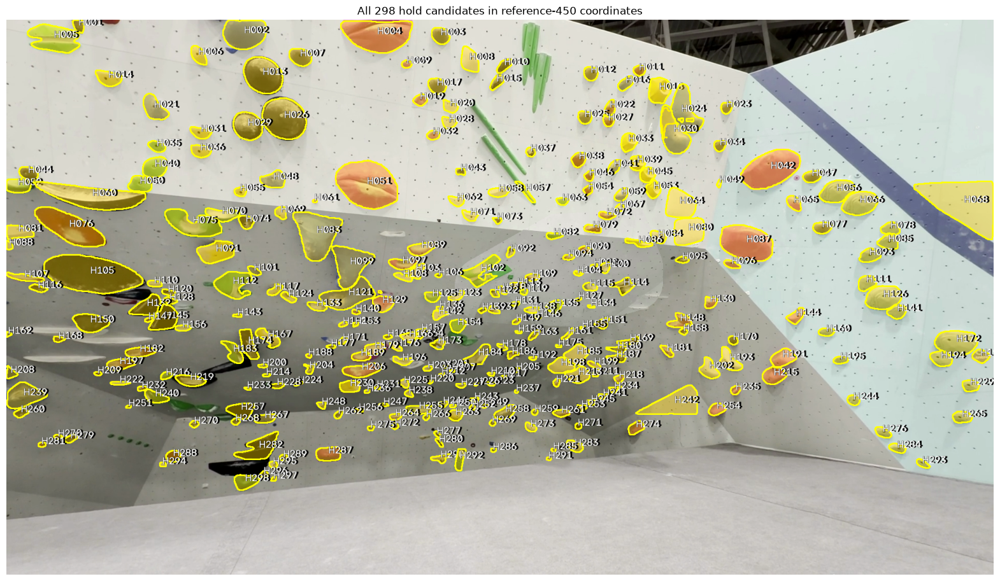

,hold_id,model_index,class_id,class_name,score,cx_px,cy_px,x_min,y_min,x_max,y_max,area_px,source,inference_region,review_status
0,H001,0,0,hold,0.975491,140.263158,11.061404,128,0,150,25,456,multiframe_tiled_model,tile_0_0,unreviewed_auto_candidate
1,H002,1,0,hold,0.993129,462.816850,26.345543,421,0,506,57,4095,multiframe_tiled_model,tile_0_0,unreviewed_auto_candidate
2,H003,2,0,hold,0.994472,844.197662,30.304995,827,15,862,47,941,multiframe_tiled_model,tile_576_0,unreviewed_auto_candidate
3,H004,3,0,hold,0.996670,721.929979,28.548691,650,2,789,64,6798,multiframe_tiled_model,whole,unreviewed_auto_candidate
4,H005,4,0,hold,0.970819,92.988673,35.964048,41,8,142,64,4061,multiframe_tiled_model,tile_0_0,unreviewed_auto_candidate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,H294,293,0,hold,0.827610,303.961538,865.153846,298,861,310,869,104,multiframe_tiled_model,tile_0_312,unreviewed_auto_candidate
294,H295,294,0,hold,0.877252,518.650273,865.306011,511,859,527,872,183,multiframe_tiled_model,tile_0_312,unreviewed_auto_candidate
295,H296,295,0,hold,0.953373,500.925714,884.651429,492,878,509,891,175,multiframe_tiled_model,tile_0_312,unreviewed_auto_candidate
296,H297,296,0,hold,0.775236,519.696203,893.405063,514,889,524,897,79,multiframe_tiled_model,tile_0_312,unreviewed_auto_candidate


Full-resolution candidate map: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/images/all_hold_candidates.png
All candidates are visible, including previously excluded or uncertain detections.
Edit USER_ROUTE_HOLD_IDS in the next code cell to select the route.


In [5]:
HOLD_MAP_PATH = STATE_DIR / 'reviewed_hold_map.npz'
if USE_SAVED_HOLD_MAP and not HOLD_MAP_PATH.is_file():
    if REFERENCE_FRAME == 0:
        restore_reviewed_map(PROJECT_DIR / 'data/reviewed_contact_data.zip', HOLD_MAP_PATH, VIDEO_FILE, reference_frame_number=REFERENCE_FRAME)
    else:
        USE_SAVED_HOLD_MAP = False

# A later reference can cover holds that were outside the opening shot.
reference_frame = read_frame(VIDEO_FILE, REFERENCE_FRAME)
wall_image = reference_frame.copy()
print('Wall reference:', REFERENCE_FRAME, '| video:', VIDEO_FILE)
print('Reference size:', wall_image.shape[:2])
cv2.imwrite(str(IMAGES_DIR / 'wall_reference.jpg'), wall_image)
if USE_SAVED_HOLD_MAP:
    with np.load(HOLD_MAP_PATH, allow_pickle=False) as saved:
        saved_reference = json.loads(str(saved['metadata']))['reference_frame_number']
    if saved_reference != REFERENCE_FRAME:
        print('Reference changed: detecting a new hold map and assigning new IDs.')
        USE_SAVED_HOLD_MAP = False

if USE_SAVED_HOLD_MAP:
    candidate_records, candidate_masks, candidate_run_id, saved_selected_hold_ids = load_reviewed_holds(
        HOLD_MAP_PATH, VIDEO_FILE, reference_frame_number=REFERENCE_FRAME)
    with np.load(HOLD_MAP_PATH, allow_pickle=False) as saved:
        wall_image = saved['reference_frame'].copy()
    cv2.imwrite(str(IMAGES_DIR / 'wall_reference.jpg'), wall_image)
    print(f'Loaded saved hold map: {len(candidate_masks)} candidate IDs, {len(saved_selected_hold_ids)} selected')
else:
    from detectron2.config import get_cfg
    from detectron2.engine import DefaultPredictor

    hold_cfg = get_cfg()
    hold_cfg.merge_from_file(str(MODELS_DIR / 'experiment_config.yml'))
    hold_cfg.MODEL.WEIGHTS = str(MODELS_DIR / 'model_final.pth')
    # CPU is slower but avoids requiring a GPU build for this single image.
    hold_cfg.MODEL.DEVICE = 'cpu'
    SCORE_THRESHOLD = 0.70
    hold_cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = SCORE_THRESHOLD
    hold_predictor = DefaultPredictor(hold_cfg)
    hold_instances = hold_predictor(wall_image)['instances'].to('cpu')
    if not hold_instances.has('pred_masks'):
        raise ValueError('The loaded model did not return instance masks. Check the model/config pair.')

def build_hold_candidates(masks, scores, classes):
    """Keep pixel geometry at original image size and assign deterministic IDs per run."""
    unsorted = []
    for model_index, (mask, score, class_id) in enumerate(zip(masks, scores, classes)):
        ys, xs = np.nonzero(mask)
        if len(xs) == 0:
            continue
        unsorted.append((float(ys.mean()), float(xs.mean()), model_index, {
            'model_index': int(model_index), 'class_id': int(class_id),
            'class_name': {0: 'hold', 1: 'volume'}.get(int(class_id), 'other'),
            'score': float(score), 'cx_px': float(xs.mean()), 'cy_px': float(ys.mean()),
            'x_min': int(xs.min()), 'y_min': int(ys.min()),
            'x_max': int(xs.max()), 'y_max': int(ys.max()), 'area_px': int(len(xs)),
            'source': 'model_prediction', 'review_status': 'unreviewed'
        }))
    records, mask_map = [], {}
    for i, (_, _, model_index, record) in enumerate(sorted(unsorted, key=lambda x: x[:3]), 1):
        record['hold_id'] = f'H{i:02d}'
        records.append(record)
        mask_map[record['hold_id']] = np.asarray(masks[model_index], dtype=bool)
    return records, mask_map

import uuid
if not USE_SAVED_HOLD_MAP:
    candidate_run_id = uuid.uuid4().hex
    candidate_records, candidate_masks = build_hold_candidates(
        hold_instances.pred_masks.numpy(), hold_instances.scores.numpy(),
        hold_instances.pred_classes.numpy())
if not candidate_records:
    raise ValueError('No candidates. Inspect the reference image and try a lower threshold.')

def render_holds(frame, ids, H=None):
    if frame.shape[:2] != wall_image.shape[:2]:
        raise ValueError('Video and reference image dimensions differ. Do not mix resized coordinates.')
    result = frame.copy()
    h, w = frame.shape[:2]
    for hold_id in ids:
        record = next(r for r in candidate_records if r['hold_id'] == hold_id)
        mask = candidate_masks[hold_id]
        if H is not None:
            mask = cv2.warpPerspective(mask.astype(np.uint8), H, (w, h),
                                       flags=cv2.INTER_NEAREST).astype(bool)
            if not mask.any():
                continue
            ys, xs = np.nonzero(mask)
            xy = (int(xs.mean()), int(ys.mean()))
        else:
            xy = (int(record['cx_px']), int(record['cy_px']))
        result[mask] = (0.6 * result[mask] + 0.4 * np.array([0, 210, 255])).astype(np.uint8)
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(result, contours, -1, (0, 255, 255), 2)
        cv2.putText(result, hold_id, xy, cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 0, 0), 4)
        cv2.putText(result, hold_id, xy, cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 1)
    return result

# Show every detected candidate before selecting the route in the next cell.
ALL_HOLD_IDS = list(candidate_masks)
all_holds_preview = render_holds(wall_image, ALL_HOLD_IDS)
all_holds_path = IMAGES_DIR / 'all_hold_candidates.png'
cv2.imwrite(str(all_holds_path), all_holds_preview)
plt.figure(figsize=(20, 12))
plt.imshow(cv2.cvtColor(all_holds_preview, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title(f'All {len(ALL_HOLD_IDS)} hold candidates in reference-{REFERENCE_FRAME} coordinates')
plt.show()
display(pd.DataFrame(candidate_records))
print('Full-resolution candidate map:', all_holds_path)
print('All candidates are visible, including previously excluded or uncertain detections.')
print('Edit USER_ROUTE_HOLD_IDS in the next code cell to select the route.')


### 4B. Select the route from the full candidate map

The previous code cell displays **all detected candidates**, including previously
excluded or uncertain detections. It does not change the saved route selection.

Edit **`USER_ROUTE_HOLD_IDS`** at the top of the next code cell: add any missing
IDs and remove unwanted ones. The saved IDs are a starting list. Run that
cell to preview and save only your chosen route holds, then rerun Section 6 onward
to refresh contact predictions. List order does not specify movement order.

After editing, save this notebook so its code keeps your latest list. The final
evaluation cell reads the saved route and refreshes its tables and images.


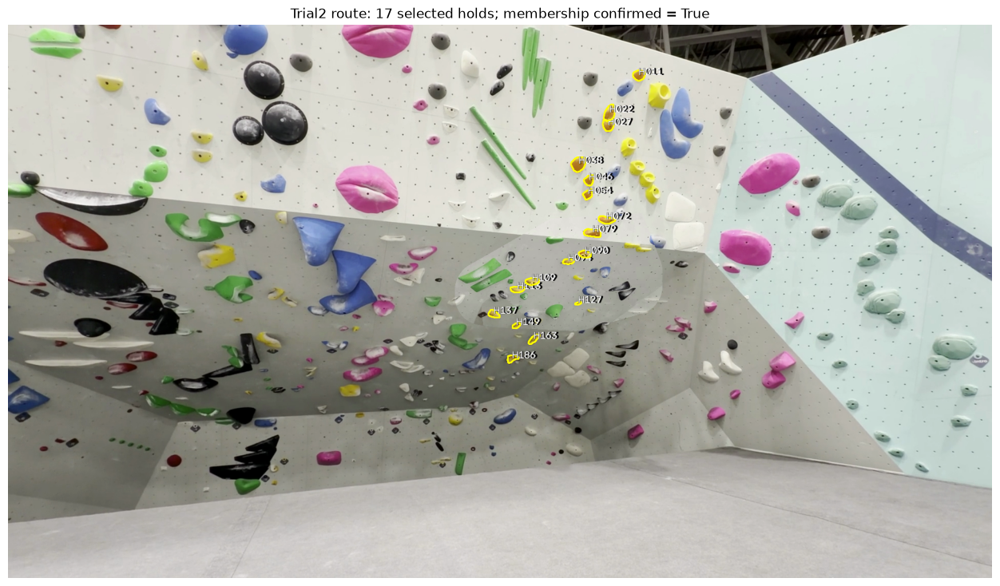

Saved route selection: ['H137', 'H113', 'H109', 'H163', 'H094', 'H090', 'H079', 'H072', 'H054', 'H046', 'H038', 'H027', 'H022', 'H011', 'H127', 'H149', 'H186']
Route membership confirmed: True | Contact timing remains unconfirmed.


In [6]:
# Edit this list to add or remove route holds from the full map above.
USER_ROUTE_HOLD_IDS = ['H137', 'H113', 'H109', 'H163', 'H094', 'H090', 'H079', 'H072', 'H054', 'H046', 'H038', 'H027', 'H022', 'H011', 'H127', 'H149', 'H186']
USER_ROUTE_CANDIDATE_RUN_ID = 'ea806103e4af44ceb85fbfd48fac1ec8'
if candidate_run_id != USER_ROUTE_CANDIDATE_RUN_ID:
    raise ValueError('The candidate map changed. Review the new IDs and update this route list and its map run ID.')
SELECTED_HOLD_IDS = list(USER_ROUTE_HOLD_IDS)
if not SELECTED_HOLD_IDS:
    raise ValueError('Enter the relevant predicted hold IDs in SELECTED_HOLD_IDS, then rerun.')
if len(set(SELECTED_HOLD_IDS)) != len(SELECTED_HOLD_IDS):
    raise ValueError('Remove duplicate hold IDs.')
invalid = set(SELECTED_HOLD_IDS) - set(candidate_masks)
if invalid:
    raise ValueError(f'Unknown hold IDs: {invalid}')
selected_hold_ids = list(SELECTED_HOLD_IDS)
reviewed_run_id = candidate_run_id
route_confirmed = (candidate_run_id == USER_ROUTE_CANDIDATE_RUN_ID
                   and set(selected_hold_ids) == set(USER_ROUTE_HOLD_IDS))
reviewed_records = [dict(r, route_membership='user_confirmed' if route_confirmed else 'unconfirmed')
                    for r in candidate_records if r['hold_id'] in selected_hold_ids]
plt.figure(figsize=(16, 9))
plt.imshow(cv2.cvtColor(render_holds(wall_image, selected_hold_ids), cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title(f'Trial2 route: {len(selected_hold_ids)} selected holds; membership confirmed = {route_confirmed}')
plt.show()

save_reviewed_holds(HOLD_MAP_PATH, VIDEO_FILE, wall_image, candidate_records,
                    candidate_masks, candidate_run_id, selected_hold_ids,
                    reference_frame_number=REFERENCE_FRAME)
selection_status = {
    'status': 'user_confirmed_route' if route_confirmed else 'unconfirmed_route',
    'selected_hold_ids': selected_hold_ids, 'reference_frame': REFERENCE_FRAME,
    'candidate_run_id': candidate_run_id, 'video_sha256': VIDEO_HASH,
    'reviewed_map_sha256': file_sha256(HOLD_MAP_PATH),
    'source': 'Manual notebook route selection',
    'route_hold_ids': list(USER_ROUTE_HOLD_IDS),
    'order_is_movement_sequence': False,
    'limitation': 'Route membership only. Contact identities, release/arrival and continuous supports still require review.'
}
(STATE_DIR / 'hold_selection_status.json').write_text(json.dumps(selection_status, indent=2) + '\n')
print('Saved route selection:', selected_hold_ids)
print('Route membership confirmed:', route_confirmed, '| Contact timing remains unconfirmed.')


### 4C. Geometry assumptions: hole spacing, source height and floor lines

Use the original reference frame for geometric measurements; the reconstructed image can contain
small seam distortions. Orange/blue segments mark assistant-selected adjacent-hole samples in two
wall regions. Each marked interval is assumed to be 15 cm; neither a square grid nor a wall angle
is assumed. F1 and F2 were confirmed by the user as parallel floor lines.

Change spacing or source height in Section 1, then rerun this cell. The point coordinates and their
review status are stored in `data/trial2_geometry_reference.json`; new videos/reference frames need
new point selections. These local scales stay separate from the global `PX_PER_CM` used by legacy IK.


Source climber: **173 cm** | Target user: **190 cm** | Assumed hole spacing: **15 cm**

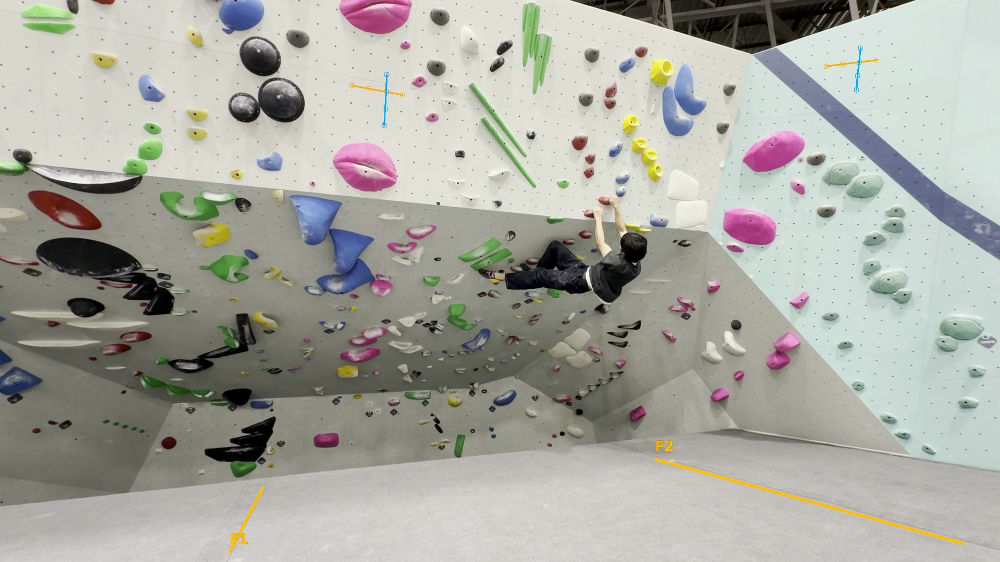

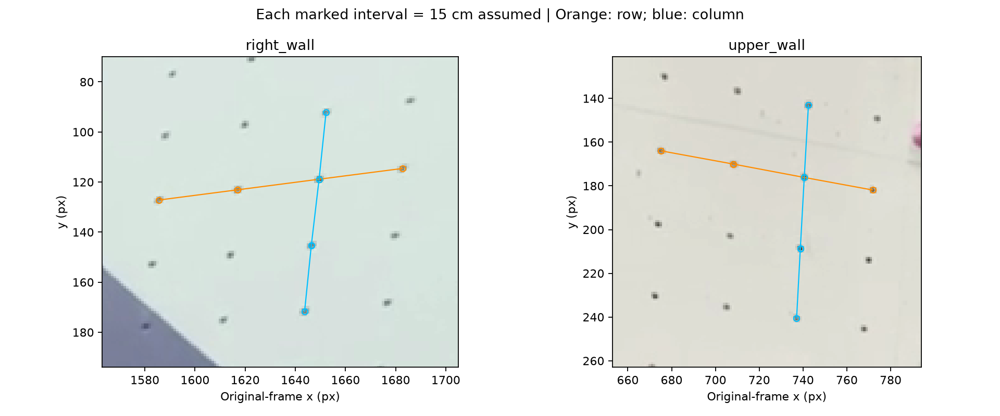

,sample_id,panel_id,direction,intervals,assumed_length_cm,image_distance_px,local_px_per_cm,review_status
0,upper_row_1,upper_wall,row,1,15.0,33.651967,2.243464,assistant_selected_draft
1,upper_row_2,upper_wall,row,1,15.0,32.839625,2.189308,assistant_selected_draft
2,upper_row_3,upper_wall,row,1,15.0,31.866730,2.124449,assistant_selected_draft
3,upper_column_1,upper_wall,column,1,15.0,33.074619,2.204975,assistant_selected_draft
4,upper_column_2,upper_wall,column,1,15.0,32.489347,2.165956,assistant_selected_draft
5,upper_column_3,upper_wall,column,1,15.0,31.975756,2.131717,assistant_selected_draft
6,right_row_1,right_wall,row,1,15.0,31.502717,2.100181,assistant_selected_draft
7,right_row_2,right_wall,row,1,15.0,32.824992,2.188333,assistant_selected_draft
8,right_row_3,right_wall,row,1,15.0,33.566562,2.237771,assistant_selected_draft
9,right_column_1,right_wall,column,1,15.0,26.763731,1.784249,assistant_selected_draft


Floor vanishing point: {'homogeneous': [622.6119174942704, 708.1269098548509, 1.0], 'pixel_xy': [622.6119174942704, 708.1269098548509], 'at_infinity': False}
Wall-to-floor angle: undetermined. Global metric IK calibration: pending.
Saved: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/state/geometry_calibration.json


In [3]:
from IPython.display import Image, Markdown
from beta_translator.scene_geometry import save_geometry_run, load_geometry_run, geometry_artifacts

geometry_context = save_geometry_run(VIDEO_FILE, OUTPUTS_DIR, GEOMETRY_REFERENCE_PATH,
    REFERENCE_FRAME, HOLE_SPACING_CM, SOURCE_CLIMBER_HEIGHT_CM, TARGET_HEIGHT_CM, RATIOS)
display(Markdown(f"Source climber: **{SOURCE_CLIMBER_HEIGHT_CM} cm** | Target user: **{TARGET_HEIGHT_CM} cm** | Assumed hole spacing: **{HOLE_SPACING_CM:g} cm**"))
display(Image(filename=str(IMAGES_DIR / 'geometry_reference_points.jpg'), width=1200))
display(Image(filename=str(IMAGES_DIR / 'geometry_hole_details.png'), width=1100))
display(pd.DataFrame(geometry_context['local_scale_samples']))
print('Floor vanishing point:', geometry_context['floor']['vanishing_point'])
print('Wall-to-floor angle: undetermined. Global metric IK calibration: pending.')
print('Saved:', STATE_DIR / 'geometry_calibration.json')


## 5. Align the wall across frames

SIFT matches and RANSAC estimate a reference-to-current-frame homography. Unreliable frames reuse the
previous transform and are excluded from contact inference and IK.
The cache is tied to the video, exact pose CSV, and alignment settings; changed inputs trigger recomputation.

In [8]:
sift = cv2.SIFT_create(nfeatures=4000)
bf = cv2.BFMatcher(cv2.NORM_L2)

# Optional: polygon (in reference-image pixels) around the flat wall face with the route,
# e.g. np.array([[x, y], [x, y], ...]). None = use the whole frame.
WALL_ROI = None

# Builds a mask that blacks out the climber
def climber_exclusion_mask(shape, frame_idx, pad=60):
    # 255 = usable wall pixels, 0 = box around the climber
    mask = np.full(shape[:2], 255, np.uint8)
    row = pose_df[pose_df.frame == frame_idx]
    if len(row):
        r = row.iloc[0]
        xs = [r[c] for c in r.index if c.endswith('_x_px')]
        ys = [r[c] for c in r.index if c.endswith('_y_px')]
        mask[max(0, int(min(ys)) - pad):int(max(ys)) + pad,
             max(0, int(min(xs)) - pad):int(max(xs)) + pad] = 0
    return mask

# Finds SIFT features in one frame and matches them to reference-image features
def estimate_H_ref_to_frame(ref_kp, ref_des, frame_bgr, frame_idx, min_inliers=25):
    gray = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, climber_exclusion_mask(gray.shape, frame_idx))
    if des is None or len(kp) < 10:
        return None, 0
    if ref_des is None:
        return None, 0
    pairs = bf.knnMatch(ref_des, des, k=2)
    good = [p[0] for p in pairs if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
    if len(good) < min_inliers:
        return None, len(good)
    src = np.float32([ref_kp[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, inliers = cv2.findHomography(src, dst, cv2.RANSAC, 4.0)
    if H is None or not np.isfinite(H).all():
        return None, 0
    n = int(inliers.sum())
    return (H if n >= min_inliers else None), n

# Features in the selected reference frame, excluding the climber and anything outside the ROI.
# Registration stays tied to the original reference image, not the reconstructed display.
ref_gray = cv2.cvtColor(reference_frame, cv2.COLOR_BGR2GRAY)
ref_mask = climber_exclusion_mask(ref_gray.shape, REFERENCE_FRAME)
if WALL_ROI is not None:
    roi = np.zeros_like(ref_mask)
    cv2.fillPoly(roi, [WALL_ROI.astype(np.int32)], 255)
    ref_mask = cv2.bitwise_and(ref_mask, roi)
ref_kp, ref_des = sift.detectAndCompute(ref_gray, ref_mask)

ALIGNMENT_PATH = STATE_DIR / 'alignment_cache.npz'
alignment_settings = dict(reference_frame_number=REFERENCE_FRAME, nfeatures=4000, min_inliers=25, ratio_test=0.75,
                          ransac_threshold=4.0, exclusion_pad=60,
                          wall_roi=None if WALL_ROI is None else WALL_ROI.tolist())
homographies = load_alignment(ALIGNMENT_PATH, VIDEO_FILE, POSE_PATH, alignment_settings)
if homographies is None:
    # Get homography for each frame
    homographies = {}          # frame index -> (H, inlier_count, 'ok' | 'reused')
    last_H = np.eye(3)
    cap = cv2.VideoCapture(VIDEO_FILE)
    i = 0
    while True:
        ok, f = cap.read()
        if not ok:
            break
        if i == REFERENCE_FRAME:
            H, n = np.eye(3), len(ref_kp)
        else:
            H, n = estimate_H_ref_to_frame(ref_kp, ref_des, f, i)
        if H is None:
            H, status = last_H, 'reused'   # fall back to the previous frame's transform
        else:
            last_H, status = H, 'ok'
        homographies[i] = (H, n, status)
        i += 1
    cap.release()
    
    if not homographies:
        raise ValueError('No video frames were available for alignment.')
    save_alignment(ALIGNMENT_PATH, homographies, VIDEO_FILE, POSE_PATH, alignment_settings)
else:
    print('Loaded matching alignment cache.')
bad = [k for k, v in homographies.items() if v[2] != 'ok']
print(f'{len(homographies)} frames; {len(bad)} reused alignments.')


Loaded matching alignment cache.
976 frames; 0 reused alignments.


## 6. Draft limb contacts

The matcher compares wrists and foot-index landmarks with selected hold masks in each video frame.
A unique nearby hold needs 0.5 seconds of consecutive visible evidence to become `likely_contact`.
Ambiguity, low visibility, missing poses, and unreliable alignment remain unresolved.
`no_candidate` does not mean a free limb. Margins are pixels at 720px video width, scaled to the input.

This adapts the proximity and temporal filtering idea described in
[The Way Up](https://arxiv.org/html/2505.12854v1), using masks instead of boxes.
The score describes geometric proximity, not a contact probability. It does not establish grip or load bearing.

In [9]:
if reviewed_run_id != candidate_run_id:
    raise ValueError('Review the current hold map first.')
CONTACT_SETTINGS = dict(hand_margin_px=20, foot_margin_px=10, min_visibility=0.5,
                        min_contact_sec=0.5, ambiguity_gap_px=3, min_inliers=25)
contact_run_id = reviewed_run_id
contact_hold_ids = tuple(selected_hold_ids)
contact_masks = {hold: candidate_masks[hold].copy() for hold in contact_hold_ids}
contacts_df, contact_events_df, contact_fps = match_limb_contacts(
    pose_df, contact_masks, homographies, VIDEO_FILE, **CONTACT_SETTINGS)

contacts_df.to_csv(TABLES_DIR / 'limb_contacts.csv', index=False)
contact_events_df.to_csv(TABLES_DIR / 'contact_events.csv', index=False)
(STATE_DIR / 'contact_settings.json').write_text(json.dumps(dict(
    settings=CONTACT_SETTINGS, video=str(VIDEO_FILE), video_sha256=file_sha256(VIDEO_FILE),
    pose_sha256=file_sha256(POSE_PATH), alignment_sha256=file_sha256(ALIGNMENT_PATH), fps=contact_fps,
    selected_holds=contact_hold_ids, candidate_run_id=contact_run_id,
    coordinates='original current-frame pixels', margins='pixels at 720px image width',
    interval='start_frame/end_frame inclusive; end_sec exclusive',
    match_score='geometric proximity only, not a probability'), indent=2))
display(pd.crosstab(contacts_df['limb'], contacts_df['status']))
display(contact_events_df)
print(f'Saved {len(contacts_df)} limb observations and {len(contact_events_df)} draft intervals to {TABLES_DIR}.')


status,ambiguous,likely_contact,low_visibility,missing_pose,no_candidate,tentative
limb,,,,,,
left_foot,37,325,278,14,240,82
left_hand,103,506,218,14,5,130
right_foot,17,98,624,14,160,63
right_hand,62,366,490,14,8,36


,limb,hold_id,start_frame,end_frame,start_sec,end_sec,duration_sec,min_visibility,min_match_score
0,left_hand,H137,0,92,0.000000,3.100000,3.100000,0.530057,0.665926
1,left_hand,H137,94,125,3.133333,4.200000,1.066667,0.642795,0.789661
2,left_hand,H109,317,357,10.566667,11.933333,1.366667,0.514091,0.656071
3,left_hand,H079,364,510,12.133333,17.033333,4.900000,0.803836,0.799343
4,left_hand,H054,513,609,17.100000,20.333333,3.233333,0.820393,0.729824
5,left_hand,H022,852,882,28.400000,29.433333,1.033333,0.597791,0.988143
6,left_hand,H022,897,961,29.900000,32.066667,2.166667,0.584123,0.650594
7,right_hand,H137,36,80,1.200000,2.700000,1.500000,0.507727,0.641395
8,right_hand,H137,98,117,3.266667,3.933333,0.666667,0.564185,0.543260
9,right_hand,H109,130,182,4.333333,6.100000,1.766667,0.854105,0.762540


Saved 3904 limb observations and 29 draft intervals to /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/tables.


## 6B. Learned contact and timing proposals

Reuse verified RTMW features and the trained temporal ensemble. Predictions stay separate from reviewed tables. The main kernel uses `.venv`; inference uses `.venv-contact`.


In [10]:
# Inference uses a separate interpreter; the current MediaPipe/IK kernel is unchanged.
import subprocess
from beta_translator.contact_review import load_review_bundle, review_annotation_from_prediction

CONTACT_PYTHON = PROJECT_DIR / '.venv-contact/bin/python'
CONTACT_PACKAGE = MODELS_DIR / 'contact_v1'
AUTOMATIC_DIR = OUTPUTS_DIR / 'automatic'
AUTOMATIC_PREDICTIONS = AUTOMATIC_DIR / 'predictions'
WHOLEBODY_CACHE = AUTOMATIC_DIR / 'wholebody.npz'
REFRESH_AUTOMATIC = False  # Set True to recompute proposals from verified pose features.

def get_automatic_review_bundle(refresh=False):
    arguments = (VIDEO_FILE, OUTPUTS_DIR, WHOLEBODY_CACHE, CONTACT_PACKAGE, AUTOMATIC_PREDICTIONS)
    if not refresh:
        try:
            return load_review_bundle(*arguments)
        except (FileNotFoundError, ValueError, KeyError) as error:
            print(f'Prediction cache needs refresh: {error}')
    if not CONTACT_PYTHON.is_file():
        raise FileNotFoundError('Create .venv-contact with requirements-contact.txt; see README. Keep this notebook on .venv.')
    result = subprocess.run([str(CONTACT_PYTHON), '-m', 'beta_translator.contact_runner',
        '--video', str(VIDEO_FILE), '--outputs', str(OUTPUTS_DIR),
        '--package', str(CONTACT_PACKAGE)], cwd=PROJECT_DIR, text=True, capture_output=True)
    print(result.stdout)
    if result.returncode:
        raise RuntimeError(result.stderr or 'Automatic inference failed.')
    return load_review_bundle(*arguments)

automatic_prediction, automatic_contacts = get_automatic_review_bundle(REFRESH_AUTOMATIC)
print('Learned proposals, zero-based native frames. Contact and timing suggestions need review.')
display(pd.DataFrame(automatic_prediction['moves'])[[
    'moving_limb', 'from_hold', 'to_hold', 'before_frame', 'after_frame',
    'release_frame', 'arrival_frame', 'requires_review']])


Learned proposals, zero-based native frames. Contact and timing suggestions need review.


,moving_limb,from_hold,to_hold,before_frame,after_frame,release_frame,arrival_frame,requires_review
0,left_hand,H137,H109,171,225,179,218,True
1,left_hand,H109,H079,345,461,353,454,True
2,left_hand,H079,H054,499,529,507,522,True
3,left_hand,H054,H038,654,682,662,675,True
4,left_hand,H038,H022,817,848,825,841,True
5,left_hand,H022,H011,951,975,959,969,True
6,right_hand,H137,H109,72,227,80,220,True
7,right_hand,H109,H090,264,371,272,364,True
8,right_hand,H090,H072,420,477,428,470,True
9,right_hand,H072,H046,583,618,591,611,True


## 7. Review drafts and confirm BEFORE/AFTER contacts

One viewer now shows the raw frame, hold outlines, contact predictions, and manual endpoint controls.
Inspect one clear movement. Set each endpoint, then explicitly choose its four contact labels.
Use the explicit prefill control to copy suggestions; support confirmation remains manual. Left/right refer to the climber's anatomy.

Use `unknown` for occlusion, `free` for an observed limb off the wall, and `wall_contact` for a smear.
Save the annotations before restarting; Load restores matching video/map annotations.
Changing an endpoint resets its four labels so an old frame's contacts cannot carry over silently.
Foot predictions use foot-index landmarks; IK uses ankles as an approximation, so review foot contacts carefully.

For continuous IK, enter release (first free frame) and arrival (first new-contact frame),
then confirm the other three contacts were maintained throughout. Leave both at -1 for endpoint-only work.
Changing endpoints, contact labels, or the moving limb clears this motion review. Save again after edits.


Use **Prefill automatic draft** for learned suggestions. Change BEFORE/AFTER, contact IDs and release/arrival as needed. Confirm the three supports only after reviewing their continuity. Any contact or timing edit clears that confirmation. The overlay remains the geometric baseline; the second table shows learned-model labels.

The manual form is optional when `AUTOMATIC_IK_ENABLED` is enabled. Section 7B builds inputs directly from the model; the manual form continues to support explicit corrections.


In [11]:
CONTACT_COLORS = {'likely_contact': 'limegreen', 'tentative': 'darkorange',
                  'ambiguous': 'darkorange', 'no_candidate': 'deepskyblue'}
CONTACT_LABELS = {'left_hand': 'LH', 'right_hand': 'RH', 'left_foot': 'LF', 'right_foot': 'RF'}
contact_form_run_id = reviewed_run_id
annotation_hold_ids = tuple(selected_hold_ids)
annotation_count = int(contacts_df['frame'].max()) + 1
ANNOTATION_PATH = STATE_DIR / 'endpoint_annotations.json'
automatic_review_evidence = None


def check_review_state():
    if (contact_form_run_id != candidate_run_id or contact_run_id != candidate_run_id
            or annotation_hold_ids != tuple(selected_hold_ids) or contact_hold_ids != annotation_hold_ids):
        raise ValueError('The reviewed route changed. Rerun contact matching and this viewer.')


def plot_contact_frame(frame_index, ax=None):
    check_review_state()
    frame = read_frame(VIDEO_FILE, frame_index)
    entry = homographies.get(frame_index)
    if entry is not None and entry[2] == 'ok':
        frame = render_holds(frame, contact_hold_ids, entry[0])
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    for row in contacts_df.loc[contacts_df.frame == frame_index].itertuples():
        if not np.isfinite([row.x_px, row.y_px]).all():
            continue
        color = CONTACT_COLORS.get(row.status, 'gray')
        margin = CONTACT_SETTINGS['hand_margin_px' if 'hand' in row.limb else 'foot_margin_px']
        radius = margin * frame.shape[1] / 720
        ax.add_patch(plt.Circle((row.x_px, row.y_px), radius, fill=False, color=color))
        hold = row.candidate_hold if pd.notna(row.candidate_hold) else '?'
        ax.annotate(f'{CONTACT_LABELS[row.limb]} {hold}', (row.x_px, row.y_px),
                    xytext=(6, -14), textcoords='offset points', color=color, fontsize=9,
                    bbox=dict(facecolor='black', alpha=0.6, edgecolor='none', pad=1))
    ax.set_title(f'Frame {frame_index} | {frame_index/contact_fps:.2f}s')
    ax.axis('off')
    return ax


frame_slider = widgets.IntSlider(min=0, max=annotation_count-1, description='Frame',
                                 continuous_update=False, layout=widgets.Layout(width='500px'))
preview_output = widgets.Output()
action_output = widgets.Output()
chosen_info = widgets.HTML('Choose both endpoint frames.')
chosen_frames = {'before': None, 'after': None}
contact_choices = ['unknown', 'free', 'wall_contact'] + list(annotation_hold_ids)
contact_widgets = {limb: {phase: widgets.Dropdown(options=contact_choices, value='unknown',
                         layout=widgets.Layout(width='150px')) for phase in chosen_frames} for limb in LIMBS}
moving_limb = widgets.Dropdown(options=LIMBS, description='Moving limb', style={'description_width': 'initial'})
annotation_notes = widgets.Textarea(description='Notes', layout=widgets.Layout(width='500px'))
release_frame = widgets.IntText(value=-1, description='Release frame',
    style={'description_width': 'initial'}, layout=widgets.Layout(width='240px'))
arrival_frame = widgets.IntText(value=-1, description='Arrival frame',
    style={'description_width': 'initial'}, layout=widgets.Layout(width='240px'))
supports_confirmed = widgets.Checkbox(value=False, description='Other three contacts maintained throughout',
    indent=False, layout=widgets.Layout(width='500px'))


def clear_motion_review(change=None):
    invalidate_support_confirmation()
    release_frame.value = -1
    arrival_frame.value = -1
    supports_confirmed.value = False


def invalidate_support_confirmation(change=None):
    supports_confirmed.value = False
    if automatic_review_evidence is not None:
        automatic_review_evidence.pop('saved_confirmation_sha256', None)


def motion_state():
    if release_frame.value == -1 and arrival_frame.value == -1 and not supports_confirmed.value:
        return None
    return dict(release_frame=release_frame.value, arrival_frame=arrival_frame.value,
                support_contacts_maintained=supports_confirmed.value)



def show_contact_preview(change=None):
    with preview_output:
        preview_output.clear_output(wait=True)
        ax = plot_contact_frame(frame_slider.value)
        plt.show()
        plt.close(ax.figure)
        print('Geometric baseline overlay (Section 6):')
        display(contacts_df.loc[contacts_df.frame == frame_slider.value,
                ['limb', 'candidate_hold', 'hold_id', 'visibility', 'status']])
        print('Learned model contacts (Section 6B):')
        display(automatic_contacts.loc[automatic_contacts.frame == frame_slider.value,
                ['limb', 'hold_id', 'confidence', 'status']])


def choose_endpoint(phase):
    check_review_state()
    if chosen_frames[phase] != frame_slider.value:
        clear_motion_review()
        chosen_frames[phase] = frame_slider.value
        for limb in LIMBS:
            contact_widgets[limb][phase].value = 'unknown'
    chosen_info.value = f"BEFORE: {chosen_frames['before']} | AFTER: {chosen_frames['after']}"


def annotation_state():
    check_review_state()
    result = dict(video_sha256=VIDEO_HASH, candidate_run_id=contact_form_run_id,
                selected_hold_ids=list(annotation_hold_ids), frames=dict(chosen_frames),
                contacts={phase: {limb: contact_widgets[limb][phase].value for limb in LIMBS}
                          for phase in chosen_frames},
                moving_limb=moving_limb.value, notes=annotation_notes.value,
                body=dict(height_cm=TARGET_HEIGHT_CM, ratios=dict(RATIOS), px_per_cm=PX_PER_CM))
    if REFERENCE_FRAME != 0:
        result['reference_frame_number'] = REFERENCE_FRAME
    motion = motion_state()
    if motion is not None:
        result['motion'] = motion
    if automatic_review_evidence is not None:
        result['automatic_review'] = json.loads(json.dumps(automatic_review_evidence))
    return result


def save_review(_=None):
    with action_output:
        action_output.clear_output(wait=True)
        try:
            save_annotations(ANNOTATION_PATH, annotation_state(), VIDEO_FILE,
                             contact_form_run_id, annotation_hold_ids, annotation_count)
            print('Saved endpoint annotations:', ANNOTATION_PATH)
            return True
        except ValueError as error:
            print(error)
            return False


def load_review(_=None):
    global TARGET_HEIGHT_CM, RATIOS, PX_PER_CM, automatic_review_evidence
    with action_output:
        action_output.clear_output(wait=True)
        try:
            check_review_state()
            data = load_annotations(ANNOTATION_PATH, VIDEO_FILE, contact_form_run_id,
                                    annotation_hold_ids, annotation_count)
            chosen_frames.update(data['frames'])
            for phase in chosen_frames:
                for limb in LIMBS:
                    contact_widgets[limb][phase].value = data['contacts'][phase][limb]
            moving_limb.value = data['moving_limb']
            annotation_notes.value = data['notes']
            TARGET_HEIGHT_CM = data['body']['height_cm']
            RATIOS = data['body']['ratios']
            PX_PER_CM = data['body']['px_per_cm']
            motion = data.get('motion') or {}
            release_frame.value = motion.get('release_frame', -1)
            arrival_frame.value = motion.get('arrival_frame', -1)
            supports_confirmed.value = motion.get('support_contacts_maintained', False)
            chosen_info.value = f"BEFORE: {chosen_frames['before']} | AFTER: {chosen_frames['after']}"
            automatic_review_evidence = data.get('automatic_review')
            print('Loaded annotations and body/wall settings.')
        except (FileNotFoundError, ValueError) as error:
            print(error)


# Model timing is a suggestion. Applying any draft revokes support confirmation.
automatic_choices = [(f"{m['moving_limb']}: {m['from_hold']} → {m['to_hold']} ({m['release_frame']} / {m['arrival_frame']})", i)
                     for i, m in enumerate(automatic_prediction['moves'])]
automatic_move = widgets.Dropdown(options=automatic_choices, description='Model move',
    style={'description_width': 'initial'}, layout=widgets.Layout(width='500px'))
prefill_button = widgets.Button(description='Prefill automatic draft', layout=widgets.Layout(width='210px'),
                                disabled=not bool(automatic_choices))

def prefill_automatic(_=None):
    global automatic_review_evidence
    check_review_state()
    # Recheck disk inputs even if inference ran earlier in this kernel.
    prediction, contacts = load_review_bundle(
        VIDEO_FILE, OUTPUTS_DIR, WHOLEBODY_CACHE, CONTACT_PACKAGE, AUTOMATIC_PREDICTIONS)
    if prediction != automatic_prediction:
        raise ValueError('Model proposals changed. Rerun Sections 6B and 7.')
    move = prediction['moves'][automatic_move.value]
    draft = review_annotation_from_prediction(annotation_state(), move, prediction, contacts)
    automatic_review_evidence = None
    clear_motion_review()
    chosen_frames.update(draft['frames'])
    moving_limb.value = draft['moving_limb']
    for phase in chosen_frames:
        for limb in LIMBS:
            contact_widgets[limb][phase].value = draft['contacts'][phase][limb]
    release_frame.value = draft['suggested_motion']['release_frame']
    arrival_frame.value = draft['suggested_motion']['arrival_frame']
    supports_confirmed.value = False
    annotation_notes.value = draft['notes']
    automatic_review_evidence = {
        'prediction_sha256': file_sha256(AUTOMATIC_PREDICTIONS / 'automatic_contacts.json'),
        'model_config_sha256': prediction['model_config_sha256'],
        'original_suggestion': move,
        'prefill_supports_confirmed': False,
    }
    chosen_info.value = f"BEFORE: {chosen_frames['before']} | AFTER: {chosen_frames['after']}"
    frame_slider.value = chosen_frames['before']
    with action_output:
        action_output.clear_output(wait=True)
        print('Draft loaded. Review endpoints, release/arrival, then confirm the three supports and save.')
        print('Suggested ranges:', move.get('release_frame_range'), move.get('arrival_frame_range'))
        print('Ranges are model estimates; the correct frame can lie outside them.')
    return draft

prefill_button.on_click(prefill_automatic)

before_button = widgets.Button(description='Set BEFORE')
after_button = widgets.Button(description='Set AFTER')
save_button = widgets.Button(description='Save annotations')
load_button = widgets.Button(description='Load annotations')
before_button.on_click(lambda _: choose_endpoint('before'))
after_button.on_click(lambda _: choose_endpoint('after'))
save_button.on_click(save_review)
load_button.on_click(load_review)
frame_slider.observe(show_contact_preview, names='value')
moving_limb.observe(clear_motion_review, names='value')
for fields in contact_widgets.values():
    for field in fields.values():
        field.observe(clear_motion_review, names='value')
release_frame.observe(invalidate_support_confirmation, names='value')
arrival_frame.observe(invalidate_support_confirmation, names='value')
rows = [widgets.HTML('<b>Limb | BEFORE contact | AFTER contact</b>')]
for limb in LIMBS:
    rows.append(widgets.HBox([widgets.Label(limb, layout=widgets.Layout(width='110px')),
                             contact_widgets[limb]['before'], contact_widgets[limb]['after']]))
controls = widgets.VBox([automatic_move, prefill_button, frame_slider, widgets.HBox([before_button, after_button]), chosen_info,
                        moving_limb, *rows,
                        widgets.HTML('Motion: release = first free frame; arrival = first contact frame. -1 = unset.'),
                        widgets.HBox([release_frame, arrival_frame]), supports_confirmed,
                        annotation_notes, widgets.HBox([save_button, load_button]), action_output])
display(widgets.HTML('Green: likely contact · Orange: tentative/ambiguous · Blue: no candidate · Gray: unavailable'))
display(widgets.HBox([preview_output, controls]))
show_contact_preview()


HTML(value='Green: likely contact · Orange: tentative/ambiguous · Blue: no candidate · Gray: unavailable')

## 7B. Automatic predictions directly into IK

The user accepted the current trial2 analysis and enabled direct prediction-to-IK on 2026-10-30.
This run-level override uses `candidate_hold` and the model's release/arrival frames without
requiring another manual confirmation. It does not change the trained model's validation report.

The current solver handles one moving limb and three fixed hold supports. The table identifies
free feet, smears, overlapping limb changes and missing observations that this solver cannot
represent. Those states are preserved. Section 8B automatically runs compatible moves once the
wall geometry is available. The original reviewed annotations remain separate.


In [5]:
from beta_translator.direct_ik import run_direct_ik, direct_ik_table, automatic_ik_artifacts

direct_ik_plan = run_direct_ik(
    VIDEO_FILE, OUTPUTS_DIR, WHOLEBODY_CACHE, CONTACT_PACKAGE, AUTOMATIC_PREDICTIONS,
    TARGET_HEIGHT_CM, RATIOS, PX_PER_CM, SINGLE_PANEL_CONFIRMED,
    enabled=AUTOMATIC_IK_ENABLED, execute=False)
print('Automatic prediction-to-IK enabled:', direct_ik_plan['enabled'])
print('Current predictions accepted by user:', direct_ik_plan['current_prediction_user_accepted'])
print('Target height:', TARGET_HEIGHT_CM, 'cm')
print(f"Proposals: {direct_ik_plan['proposal_count']} | Supported by current solver: {direct_ik_plan['solver_compatible_count']}")
display(direct_ik_table(direct_ik_plan))
for reason in direct_ik_plan['geometry_blockers']:
    print('Geometry pending:', reason)


Automatic prediction-to-IK enabled: True
Current predictions accepted by user: True
Target height: 190 cm
Proposals: 21 | Supported by current solver: 0


,move,limb,transition,release,arrival,solver_compatible,status,reason
0,0,left_hand,H137 -> H109,179,218,False,unsupported_contact_schedule,Observed body poses are missing in this interv...
1,1,left_hand,H109 -> H079,353,454,False,unsupported_contact_schedule,Moving-limb labels differ from the proposed re...
2,2,left_hand,H079 -> H054,507,522,False,unsupported_contact_schedule,right_foot: free; the current solver requires ...
3,3,left_hand,H054 -> H038,662,675,False,unsupported_contact_schedule,right_foot: free; the current solver requires ...
4,4,left_hand,H038 -> H022,825,841,False,unsupported_contact_schedule,right_foot: free; the current solver requires ...
5,5,left_hand,H022 -> H011,959,969,False,unsupported_contact_schedule,right_foot: free; the current solver requires ...
6,6,right_hand,H137 -> H109,80,220,False,unsupported_contact_schedule,Observed body poses are missing in this interv...
7,7,right_hand,H109 -> H090,272,364,False,unsupported_contact_schedule,left_hand: contact changes within the proposed...
8,8,right_hand,H090 -> H072,428,470,False,unsupported_contact_schedule,left_hand: contact changes within the proposed...
9,9,right_hand,H072 -> H046,591,611,False,unsupported_contact_schedule,left_foot: free; the current solver requires a...


Geometry pending: PX_PER_CM is missing: local hole scales are not a whole-wall calibration.
Geometry pending: A suitable single-panel interval has not been established for the 2D solver.


## 8. Fit a target body after geometry review

Section 4C uses the assumed 15 cm hole spacing for local directional measurements and records
the filmed climber's 173 cm height separately from the target body set in Section 1. These observations
do not yet give a calibrated whole-wall metric transform or a wall angle. Keep `PX_PER_CM = None`
until suitable panel geometry is reviewed. Existing contact and timing review is still required.


In [13]:
def fit_endpoint(frame_index, contacts, height_cm, px_per_cm, ratios=None):
    """Fit one endpoint using approximate hold-center targets in a scaled 2D image."""
    if any(v is None or not np.isfinite(v) or v <= 0 for v in (height_cm, px_per_cm)):
        raise ValueError("Height and the measured reference-image scale must be positive.")
    if frame_index is None or frame_index not in homographies:
        raise ValueError("Choose a valid endpoint frame first.")
    if not (contact_form_run_id == reviewed_run_id == candidate_run_id) or annotation_hold_ids != tuple(selected_hold_ids):
        raise ValueError("Review and annotate the current hold predictions before fitting.")
    if set(contacts) != set(LIMBS):
        raise ValueError("Provide a contact state for each of the four limbs.")
    if homographies[frame_index][2] != "ok":
        raise ValueError("This frame needs a verified alignment before fitting.")

    rows = pose_df.loc[pose_df["frame"] == frame_index]
    if len(rows) != 1:
        raise ValueError("The chosen frame must have exactly one pose row.")
    row = rows.iloc[0].copy()
    image_height = wall_image.shape[0]

    # Landmarks start in frame-i pixels; hold centers are already in reference-image pixels.
    names = list(dict.fromkeys(n for triplet in LIMB_LANDMARKS.values() for n in triplet))
    points = np.array([[row[f"{n}_x_px"], row[f"{n}_y_px"]] for n in names])
    aligned = to_frame0(points, homographies, frame_index)
    if not np.isfinite(aligned).all():
        raise ValueError("Alignment produced invalid landmark coordinates.")
    for name, (x, y) in zip(names, aligned):
        row[f"{name}_x_px"], row[f"{name}_y_px"] = x, y

    holds = {r["hold_id"]: r for r in reviewed_records}
    targets = {}
    for limb in LIMBS:
        state = contacts[limb]
        if state == "free":
            targets[limb] = None
        elif state in holds:
            hold = holds[state]
            targets[limb] = image_to_wall_cm(
                [[hold["cx_px"], hold["cy_px"]]], px_per_cm, image_height,
            )[0]
        else:
            raise ValueError(f"{limb}: '{state}' needs a reviewed hold/contact point.")
    if all(target is None for target in targets.values()):
        raise ValueError("At least one known contact is needed for a wall fit.")

    body = make_body(height_cm, ratios)
    reference = pose_row_to_vector(row, px_per_cm, image_height)
    fitted, errors_cm = solve_inverse_kinematics(
        body, targets, reference,
        angle_weight=0.3 * angle_visibility_weights(row),
    )

    # Draw in the same reference frame used for the hold coordinates.
    joints = forward_kinematics(fitted, body)
    fig, ax = plt.subplots(figsize=(6, 9))
    ax.imshow(cv2.cvtColor(wall_image, cv2.COLOR_BGR2RGB))
    torso_roots = [joints.limbs[name].root for name in
                   ("left_hand", "right_hand", "right_foot", "left_foot", "left_hand")]
    torso = wall_cm_to_image(torso_roots, px_per_cm, image_height)
    ax.plot(*torso.T, "o-", color="lime", linewidth=2)
    for limb, chain in joints.limbs.items():
        pixels = wall_cm_to_image(chain, px_per_cm, image_height)
        ax.plot(*pixels.T, "o-", color="lime", linewidth=2)
        if targets[limb] is not None:
            target = wall_cm_to_image([targets[limb]], px_per_cm, image_height)[0]
            ax.plot(*target, "x", color="red", markersize=9)
    ax.set(xlim=(0, wall_image.shape[1]), ylim=(image_height, 0))
    ax.set_title(f"Frame {frame_index}: approximate 2D fit, height {height_cm:g} cm")
    ax.axis("off")
    plt.show()

    print("Distance from each fitted wrist/ankle to its hold-center target (cm):")
    print({limb: float(f'{error:.6g}') for limb, error in errors_cm.items()})
    return fitted, errors_cm


In [6]:
geometry_context = load_geometry_run(OUTPUTS_DIR, VIDEO_FILE, GEOMETRY_REFERENCE_PATH,
    REFERENCE_FRAME, HOLE_SPACING_CM, SOURCE_CLIMBER_HEIGHT_CM, TARGET_HEIGHT_CM, RATIOS)
print('Geometry:', geometry_context['assumptions'])
print('Local scales are available; global metric calibration:', geometry_context['ready_for_metric_ik'])
if PX_PER_CM is None or not SINGLE_PANEL_CONFIRMED:
    print('Static IK pending: Section 4C provides local scale samples, not a global multi-plane calibration.')
else:
    PHASE = 'after'  # Or 'before'.
    if PHASE not in chosen_frames:
        raise ValueError("Choose 'before' or 'after'.")
    if chosen_frames[PHASE] is None:
        print('Select an endpoint and confirm its contacts in Section 7 first.')
    elif PX_PER_CM is None:
        print('Enter the measured wall scale in Section 1 first.')
    else:
        fitted_pose, contact_errors_cm = fit_endpoint(
            chosen_frames[PHASE],
            {limb: contact_widgets[limb][PHASE].value for limb in LIMBS},
            TARGET_HEIGHT_CM, PX_PER_CM, ratios=RATIOS)


Geometry: {'hole_spacing_cm': 15.0, 'spacing_status': 'user_assumed_not_measured', 'spacing_definition': 'Center-to-center distance for each marked adjacent-hole interval; grid angles are not assumed.', 'source_climber_height_cm': 173.0, 'source_height_status': 'user_reported', 'target_user_height_cm': 190.0}
Local scales are available; global metric calibration: False
Static IK pending: Section 4C provides local scale samples, not a global multi-plane calibration.


## 8B. Run automatic IK candidates

With `AUTOMATIC_IK_ENABLED = True`, compatible model proposals are automatically converted into
motion annotations and sent to IK. Outputs go to `outputs/trial2/automatic/ik/move_XXX/`.
There is no manual support-confirmation step in this path. The source contacts remain model
predictions accepted for this experiment, not independently validated labels.

The run reports missing geometry or unsupported contact schedules without inventing measurements
or converting a free limb into a fixed support. Set the switch to `False` to use the existing
manual-annotation path. Section 9 continues to replay the original tracked climber.


In [7]:
geometry_context = load_geometry_run(OUTPUTS_DIR, VIDEO_FILE, GEOMETRY_REFERENCE_PATH,
    REFERENCE_FRAME, HOLE_SPACING_CM, SOURCE_CLIMBER_HEIGHT_CM, TARGET_HEIGHT_CM, RATIOS)
if AUTOMATIC_IK_ENABLED:
    direct_ik_plan = run_direct_ik(
        VIDEO_FILE, OUTPUTS_DIR, WHOLEBODY_CACHE, CONTACT_PACKAGE, AUTOMATIC_PREDICTIONS,
        TARGET_HEIGHT_CM, RATIOS, PX_PER_CM, SINGLE_PANEL_CONFIRMED,
        enabled=True, execute=True)
    print('Automatic prediction-to-IK: enabled; no manual confirmation required.')
    print(f"Target: {TARGET_HEIGHT_CM} cm | Proposed: {direct_ik_plan['proposal_count']} | Solver-compatible: {direct_ik_plan['solver_compatible_count']} | Generated: {direct_ik_plan['generated_count']}")
    display(direct_ik_table(direct_ik_plan))
    for reason in direct_ik_plan['geometry_blockers']:
        print('Geometry pending:', reason)
    for move in direct_ik_plan['moves']:
        if move['status'] == 'generated':
            display(Video(move['video_file'], embed=True, width=900))
    print('Run details:', STATE_DIR / 'direct_ik_plan.json')
else:
    geometry_context = load_geometry_run(OUTPUTS_DIR, VIDEO_FILE, GEOMETRY_REFERENCE_PATH,
        REFERENCE_FRAME, HOLE_SPACING_CM, SOURCE_CLIMBER_HEIGHT_CM, TARGET_HEIGHT_CM, RATIOS)
    print('Geometry:', geometry_context['assumptions'])
    print('Local scales are available; global metric calibration:', geometry_context['ready_for_metric_ik'])
    if PX_PER_CM is None or not SINGLE_PANEL_CONFIRMED or not ANNOTATION_PATH.is_file():
        print('Continuous IK pending: trial2 needs wall calibration, geometry review, and saved confirmed motion contacts.')
    else:
        from beta_translator.motion_pipeline import run_motion_analysis
        from IPython.display import Image
        
        check_review_state()
        saved_motion_annotations = load_annotations(
            ANNOTATION_PATH, VIDEO_FILE, contact_form_run_id, annotation_hold_ids, annotation_count)
        if saved_motion_annotations != annotation_state():
            raise ValueError('Load the saved annotations, or save your current edits, before running Section 8B.')
        motion_summary = run_motion_analysis(VIDEO_FILE, OUTPUTS_DIR)
        print('Motion contact timing:', motion_summary['annotation']['motion'])
        print('Numerical diagnostics:', json.dumps(motion_summary['metrics'], indent=2))
        display(Video(str(VIDEO_OUTPUT_DIR / 'motion_ik_h264.mp4'), embed=True, width=800))
        display(Video(str(VIDEO_OUTPUT_DIR / 'motion_ik_slow_h264.mp4'), embed=True, width=800))
        display(Image(filename=str(IMAGES_DIR / 'ik_motion_storyboard.png'), width=900))


Automatic prediction-to-IK: enabled; no manual confirmation required.
Target: 190 cm | Proposed: 21 | Solver-compatible: 0 | Generated: 0


,move,limb,transition,release,arrival,solver_compatible,status,reason
0,0,left_hand,H137 -> H109,179,218,False,unsupported_contact_schedule,Observed body poses are missing in this interv...
1,1,left_hand,H109 -> H079,353,454,False,unsupported_contact_schedule,Moving-limb labels differ from the proposed re...
2,2,left_hand,H079 -> H054,507,522,False,unsupported_contact_schedule,right_foot: free; the current solver requires ...
3,3,left_hand,H054 -> H038,662,675,False,unsupported_contact_schedule,right_foot: free; the current solver requires ...
4,4,left_hand,H038 -> H022,825,841,False,unsupported_contact_schedule,right_foot: free; the current solver requires ...
5,5,left_hand,H022 -> H011,959,969,False,unsupported_contact_schedule,right_foot: free; the current solver requires ...
6,6,right_hand,H137 -> H109,80,220,False,unsupported_contact_schedule,Observed body poses are missing in this interv...
7,7,right_hand,H109 -> H090,272,364,False,unsupported_contact_schedule,left_hand: contact changes within the proposed...
8,8,right_hand,H090 -> H072,428,470,False,unsupported_contact_schedule,left_hand: contact changes within the proposed...
9,9,right_hand,H072 -> H046,591,611,False,unsupported_contact_schedule,left_foot: free; the current solver requires a...


Geometry pending: PX_PER_CM is missing: local hole scales are not a whole-wall calibration.
Geometry pending: A suitable single-panel interval has not been established for the 2D solver.
Run details: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/state/direct_ik_plan.json


## 9. Replay the original movement on the selected reference hold map

This replay uses observed joints, not an adapted IK animation. Green indicates visibility ≥ 0.5;
gray indicates lower visibility. Missing poses and unreliable alignment are shown explicitly.
Timing matches the input video.
This video does not use `TARGET_HEIGHT_CM` or `RATIOS`. Retargeted videos, when generated, appear in Section 8B.


In [16]:
import tempfile


def preview_wall_motion():
    """Replay observed joints in reference-image pixels; this does not run IK."""
    if reviewed_run_id != candidate_run_id:
        raise ValueError("Review the current hold map first.")

    cap = cv2.VideoCapture(VIDEO_FILE)
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    if not np.isfinite(fps) or fps <= 0 or frame_count <= 0:
        raise ValueError("Could not read the source video's frame rate and frame count.")

    names = list(dict.fromkeys(name for chain in LIMB_LANDMARKS.values() for name in chain))
    links = [(chain[i], chain[i + 1]) for chain in LIMB_LANDMARKS.values() for i in (0, 1)]
    links += [("left_shoulder", "right_shoulder"), ("left_hip", "right_hip"),
              ("left_shoulder", "left_hip"), ("right_shoulder", "right_hip")]
    poses = pd.read_csv(TABLES_DIR / "pose_display_coordinates.csv").set_index("frame")
    if not poses.index.is_unique:
        raise ValueError("Pose data must contain at most one row per video frame.")
    # A neutral hold map avoids leaving the reference-frame climber in the background.
    background = render_holds(np.full_like(wall_image, 245), selected_hold_ids)
    height, width = background.shape[:2]
    output = VIDEO_OUTPUT_DIR / "wall_motion_h264.mp4"
    output.parent.mkdir(parents=True, exist_ok=True)
    uncertain_frames = 0

    with tempfile.TemporaryDirectory() as directory:
        raw_video = str(Path(directory) / "wall_motion.mp4")
        writer = cv2.VideoWriter(raw_video, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
        if not writer.isOpened():
            raise RuntimeError("Could not create the preview video.")
        try:
            for frame_index in range(frame_count):
                frame = background.copy()
                status = "tracked pose"
                if frame_index not in poses.index:
                    status = "pose unavailable"
                elif frame_index not in homographies or homographies[frame_index][2] != "ok":
                    status = "alignment unverified"
                else:
                    row = poses.loc[frame_index]
                    interpolated = row.get("pose_source") == "interpolated_display_only"
                    points = np.array([[row[f"{name}_x_px"], row[f"{name}_y_px"]] for name in names])
                    aligned = to_frame0(points, homographies, frame_index)
                    joints = {
                        name: tuple(map(int, np.rint(point)))
                        for name, point in zip(names, aligned)
                        if np.isfinite(point).all()
                    }
                    visible = {name: row[f"{name}_visibility"] >= 0.5 for name in joints}
                    if interpolated:
                        status = "INTERPOLATED - display only"
                    elif len(joints) < len(names):
                        status = "partial pose" if joints else "pose unavailable"
                    elif not all(visible.values()):
                        status = "low visibility"
                    for start, end in links:
                        if start in joints and end in joints:
                            color = (0, 165, 245) if interpolated else (45, 155, 35) if visible[start] and visible[end] else (150, 150, 150)
                            cv2.line(frame, joints[start], joints[end], color, 4, cv2.LINE_AA)
                    for name, point in joints.items():
                        color = (0, 165, 245) if interpolated else (45, 155, 35) if visible[name] else (150, 150, 150)
                        cv2.circle(frame, point, 5, color, -1, cv2.LINE_AA)
                if status != "tracked pose":
                    uncertain_frames += 1
                cv2.putText(frame, f"Frame {frame_index} | {frame_index / fps:.2f}s | {status}",
                            (12, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (40, 40, 40), 2, cv2.LINE_AA)
                cv2.putText(frame, "Green: visible | Gray: low visibility | Orange: display-only estimate", (12, 52),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (40, 40, 40), 1, cv2.LINE_AA)
                writer.write(frame)
        finally:
            writer.release()

        convert_video(raw_video, output)

    display(Video(str(output), embed=True, width=360))
    print(f"Saved {output}: {frame_count} frames at {fps:g} FPS; {uncertain_frames} frames with uncertain or missing joints.")


preview_wall_motion()


Saved /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/videos/wall_motion_h264.mp4: 976 frames at 30 FPS; 948 frames with uncertain or missing joints.


## 10. Save review samples and export the current run

Samples adapt to video length. The bundle includes the current pose data, matching alignment,
reviewed holds, draft results, and manually saved endpoints when available.
Save annotations in Section 7 before exporting. No automatic prediction is treated as a confirmed contact.
The original video and model weights remain separate local inputs.

The ZIP is written to `outputs/trial2/exports/` and keeps the same `tables/`, `images/`, and `state/`
subfolders inside. Restoring a reviewed hold map supports both this layout and the original flat bundle.


Geometry: {'hole_spacing_cm': 15.0, 'spacing_status': 'user_assumed_not_measured', 'spacing_definition': 'Center-to-center distance for each marked adjacent-hole interval; grid angles are not assumed.', 'source_climber_height_cm': 173.0, 'source_height_status': 'user_reported', 'target_user_height_cm': 190.0}
Local scales are available; global metric calibration: False


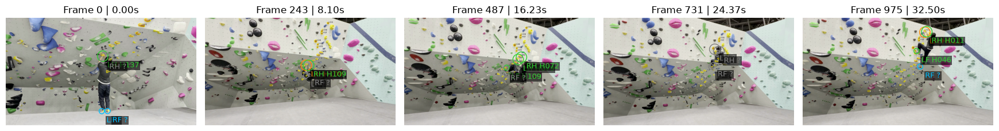

Saved local bundle: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/exports/reviewed_contact_data.zip
Manual endpoint annotations included: False


In [8]:
import importlib.metadata
import platform
import zipfile

from beta_translator.motion_pipeline import current_motion_outputs

geometry_context = load_geometry_run(OUTPUTS_DIR, VIDEO_FILE, GEOMETRY_REFERENCE_PATH,
    REFERENCE_FRAME, HOLE_SPACING_CM, SOURCE_CLIMBER_HEIGHT_CM, TARGET_HEIGHT_CM, RATIOS)
print('Geometry:', geometry_context['assumptions'])
print('Local scales are available; global metric calibration:', geometry_context['ready_for_metric_ik'])

check_review_state()
motion_paths = current_motion_outputs(VIDEO_FILE, OUTPUTS_DIR)
if load_alignment(ALIGNMENT_PATH, VIDEO_FILE, POSE_PATH, alignment_settings) is None:
    raise ValueError('Alignment no longer matches the saved inputs. Rerun Section 5 onward.')
contact_settings = json.loads((STATE_DIR / 'contact_settings.json').read_text())
if (contact_settings['pose_sha256'] != file_sha256(POSE_PATH)
        or contact_settings['alignment_sha256'] != file_sha256(ALIGNMENT_PATH)):
    raise ValueError('Contact results are outdated. Rerun Section 6 onward.')

# Sample indices are valid for short clips as well as the supplied example.
sample_frames = np.unique(np.linspace(0, annotation_count-1, min(5, annotation_count), dtype=int)).tolist()
fig, axes = plt.subplots(1, len(sample_frames), figsize=(3.5 * len(sample_frames), 7))
for ax, index in zip(np.atleast_1d(axes), sample_frames):
    plot_contact_frame(index, ax)
fig.tight_layout()
fig.savefig(IMAGES_DIR / 'contact_samples.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

saved_annotations = None
if ANNOTATION_PATH.is_file():
    saved_annotations = load_annotations(ANNOTATION_PATH, VIDEO_FILE, contact_form_run_id,
                                         annotation_hold_ids, annotation_count)
if saved_annotations is not None and any(frame is not None for frame in chosen_frames.values()) and saved_annotations != annotation_state():
    raise ValueError('Save your current endpoint annotations in Section 7 before exporting.')

direct_plan = json.loads((STATE_DIR / 'direct_ik_plan.json').read_text())
if (direct_plan['body'] != dict(height_cm=TARGET_HEIGHT_CM, ratios=dict(RATIOS), px_per_cm=PX_PER_CM)
        or direct_plan['enabled'] != AUTOMATIC_IK_ENABLED
        or direct_plan['single_panel_confirmed'] != SINGLE_PANEL_CONFIRMED
        or direct_plan['provenance']['prediction_sha256'] != file_sha256(AUTOMATIC_PREDICTIONS / 'automatic_contacts.json')):
    raise ValueError('Automatic IK settings changed. Rerun Section 7B and 8B before export.')

summary = dict(video_sha256=VIDEO_HASH, pose_rows=len(pose_df), limb_rows=len(contacts_df),
    hold_candidates=len(candidate_masks), selected_holds=list(contact_hold_ids),
    draft_intervals=len(contact_events_df), sample_frames=sample_frames,
    alignment_frames=len(homographies), alignment_fallbacks=sum(v[2] != 'ok' for v in homographies.values()),
    candidate_run_id=candidate_run_id, status_counts=pd.crosstab(contacts_df.limb, contacts_df.status).to_dict(),
    body=dict(height_cm=TARGET_HEIGHT_CM, ratios=dict(RATIOS), px_per_cm=PX_PER_CM),
    geometry=dict(assumptions=geometry_context['assumptions'],
                  provenance=geometry_context['provenance'], ready_for_metric_ik=False),
    versions=dict(python=platform.python_version(), opencv=cv2.__version__,
                  mediapipe=importlib.metadata.version('mediapipe')),
    automatic_ik=dict(enabled=direct_plan['enabled'], mode=direct_plan['mode'],
                      proposals=direct_plan['proposal_count'], generated=direct_plan['generated_count']),
    manual_endpoints_included=saved_annotations is not None, motion_results_included=bool(motion_paths),
    interpretation='Geometric drafts and reviewed annotations; no proof of grip or physical feasibility.')
(STATE_DIR / 'validation_summary.json').write_text(json.dumps(summary, indent=2))
export_path = EXPORTS_DIR / 'reviewed_contact_data.zip'
bundle_files = [
    HOLD_MAP_PATH, POSE_PATH, POSE_MANIFEST, ALIGNMENT_PATH,
    TABLES_DIR / 'limb_contacts.csv', TABLES_DIR / 'contact_events.csv',
    STATE_DIR / 'contact_settings.json', STATE_DIR / 'validation_summary.json',
    IMAGES_DIR / 'contact_samples.png',
]
if saved_annotations is not None:
    bundle_files.append(ANNOTATION_PATH)
bundle_files.extend(motion_paths)
bundle_files.extend(geometry_artifacts(OUTPUTS_DIR))
bundle_files.extend(automatic_ik_artifacts(OUTPUTS_DIR))
bundle_files.extend(path for path in [STATE_DIR / 'video_import.json', STATE_DIR / 'hold_selection_status.json', TABLES_DIR / 'source_frame_map.csv', AUTOMATIC_PREDICTIONS / 'automatic_contacts.json', AUTOMATIC_PREDICTIONS / 'limb_contacts.csv', AUTOMATIC_PREDICTIONS / 'contact_events.csv', AUTOMATIC_DIR / 'review_draft.json'] if path.is_file())
with zipfile.ZipFile(export_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in bundle_files:
        archive.write(path, path.relative_to(OUTPUTS_DIR))
print('Saved local bundle:', export_path)
print('Manual endpoint annotations included:', saved_annotations is not None)


## Multi-frame reconstruction and hold-map evaluation

**Purpose:** explain why trial2 missed holds, how the wall map was repaired, and
whether the current selected route is represented in that map.

### How the wall map is reconstructed

Frames 0, 225, 450 and 975 supply real visible pixels in frame-450 coordinates to
fill regions hidden by the climber. The original video timing is unchanged.
The detector uses the same weights and score threshold, a higher candidate cap,
and overlapping image tiles to recover smaller holds. A global homography can
still introduce errors across different wall planes.

The next cell refreshes three parts from saved files:

1. **Current route and contact results:** the selection saved in Section 4B and
   matching, verified automatic predictions.
2. **Current-route point coverage:** compare the same selected points across
   the original, higher-cap, reconstructed and tiled detector variants.
3. **Historical fixed 15-point audit:** retain the earlier experiment with its
   original points and denominator, separately from the current route.

Route selection from the final detections is not an independent detection test.
Confidence-threshold coverage is not contact accuracy or climbing-success
probability. The video below is contact inference, not adapted IK.

After changing Section 4B, rerun Section 6 onward before this cell. A stale route
or prediction cache is rejected instead of reporting mismatched results.


Rendered 250/976
Rendered 500/976
Rendered 750/976
/Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/videos/automatic_contacts_h264.mp4



### Current route: 17 selected holds

Read from the saved Section 4B selection and verified predictions:
H137, H113, H109, H163, H094, H090, H079, H072, H054, H046, H038, H027, H022, H011, H127, H149, H186.

| Current result | Value |
| --- | ---: |
| Stored detector candidates | 298 |
| Selected route holds | 17 |
| Video frames analyzed | 976 |
| Limb-frame predictions above confidence threshold | 1943/3904 (49.77%) |
| Movement proposals requiring review | 21 |
| Proposals eligible for unreviewed IK | 0 |

Confidence coverage is not contact accuracy or climbing-success probability.
Route membership does not confirm limb assignments, timing or support continuity.

### Current-route point coverage across detector variants

| Variant | Detector candidates | Selected points covered | Coverage |
| --- | ---: | ---: | ---: |
| Original frame 450, cap 100 | 100 | 6/17 | 35.3% |
| Frame 450, cap 400 | 179 | 14/17 | 82.4% |
| Reconstructed wall, cap 400 | 171 | 16/17 | 94.1% |
| Reconstruction plus overlapping tiles | 298 | 17/17 | 100.0% |

Matching uses one-to-one mask assignments within 3 reference-image pixels.
Historical source-review points are reused when available; additional points
(H163, H127) use an interior pixel of the selected mask.
The route was selected from the final detections. This measures coverage of those
selected points, not independent detection recall or all missing wall holds.

### Historical experiment: fixed 15-point development audit

The original audit is preserved with its original points and denominator:

| Variant | Original audit points covered |
| --- | ---: |
| Original frame 450, cap 100 | 6/15 |
| Frame 450, cap 400 | 13/15 |
| Reconstructed wall, cap 400 | 14/15 |
| Reconstruction plus overlapping tiles | 15/15 |

This historical sample is separate from the current route. The original spot
check of 40 raw candidates found 36 likely holds, 3 clear non-holds and 1 uncertain
object. Neither experiment establishes segmentation AP or contact accuracy.


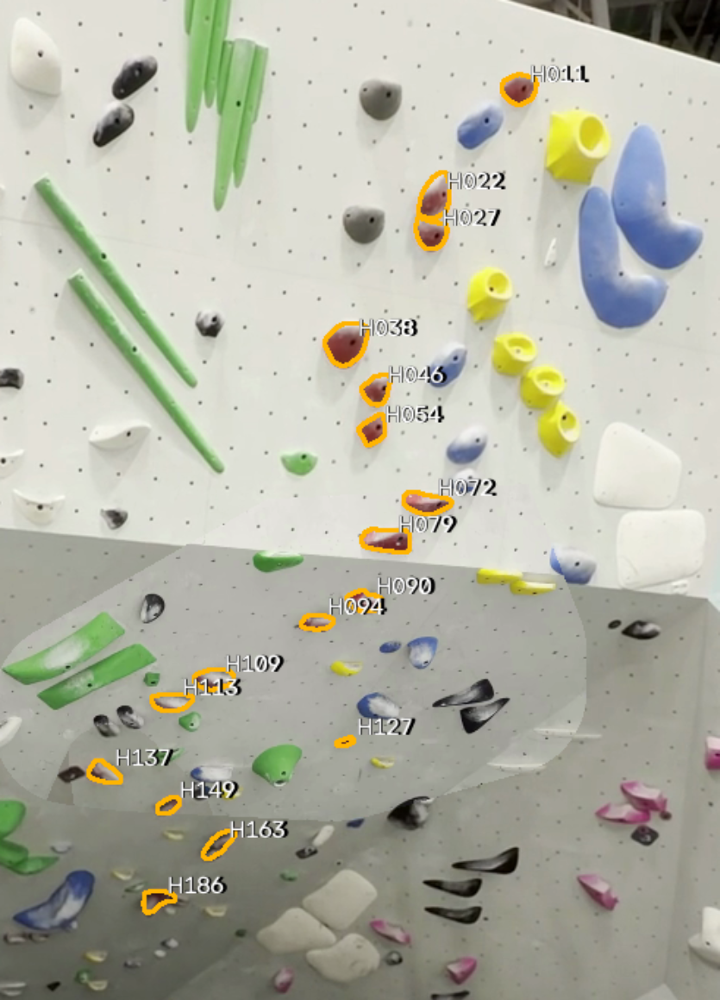

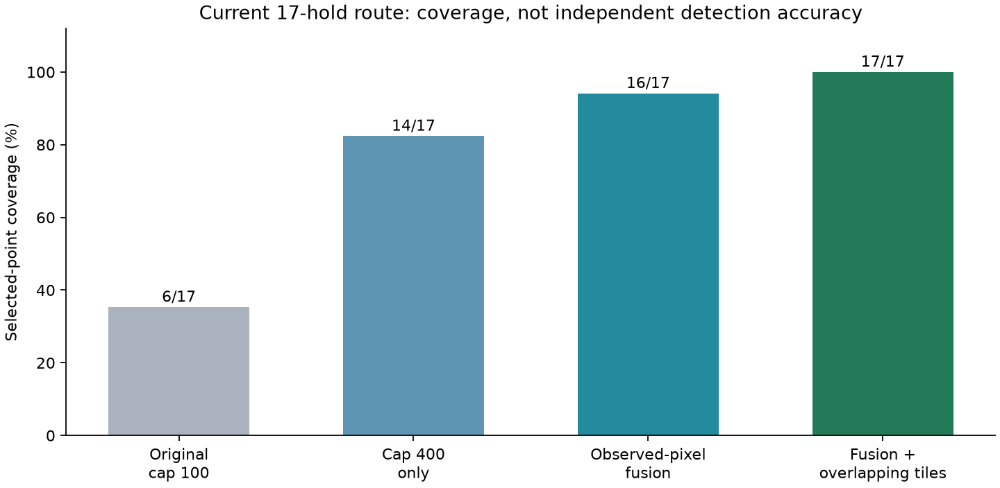

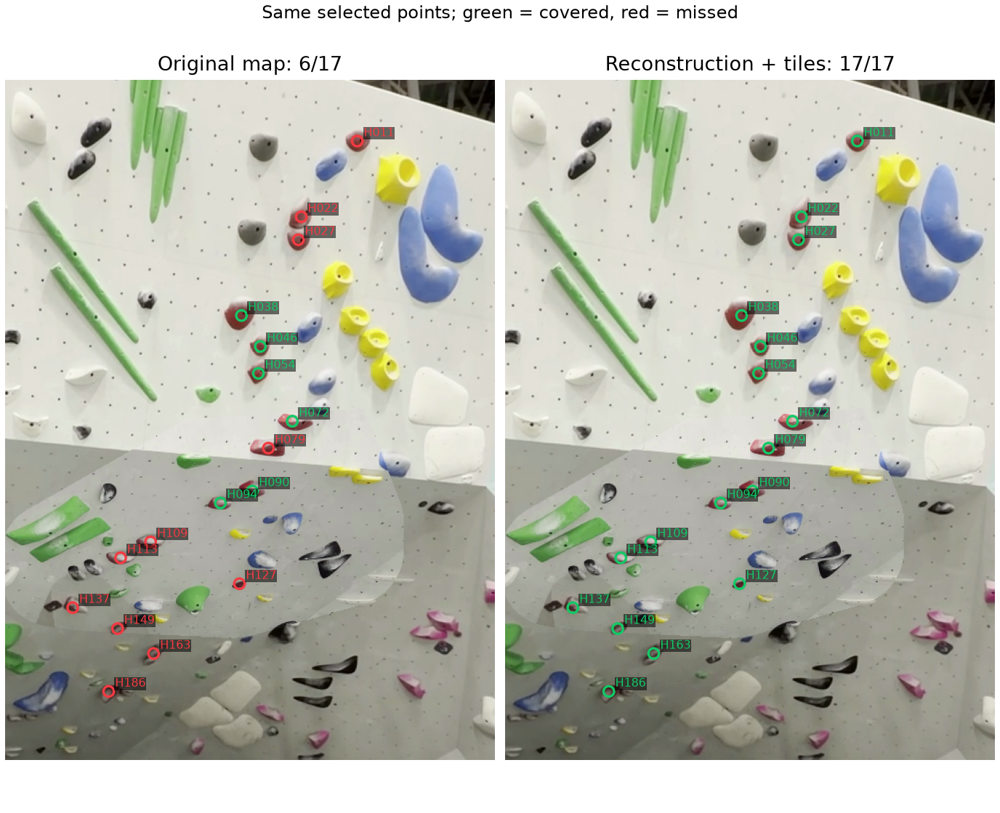

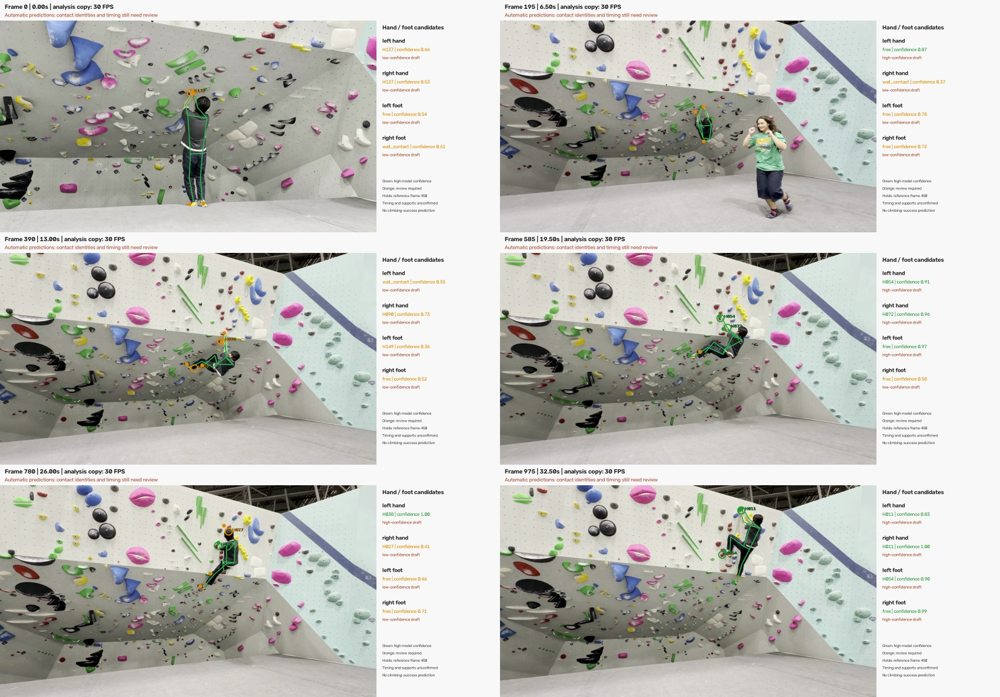

Updated report: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/reports/hold_map_evaluation.html


In [18]:
import subprocess
from IPython.display import Image, Markdown

# Reject stale identity/contact inputs before refreshing any displayed outputs.
from beta_translator.contact_review import load_review_bundle
load_review_bundle(VIDEO_FILE, OUTPUTS_DIR, OUTPUTS_DIR / 'automatic/wholebody.npz',
    MODELS_DIR / 'contact_v1', OUTPUTS_DIR / 'automatic/predictions')
# Refresh the video first so report hashes and previews refer to the same run.
rendered = subprocess.run([sys.executable, str(PROJECT_DIR / 'scripts/render_contact_video.py'),
    '--video', VIDEO_FILE, '--outputs', str(OUTPUTS_DIR)],
    cwd=PROJECT_DIR, capture_output=True, text=True)
if rendered.returncode:
    raise RuntimeError(rendered.stderr)
print(rendered.stdout)

refreshed = subprocess.run([sys.executable, str(PROJECT_DIR / 'scripts/update_trial2_report.py'),
    '--outputs', str(OUTPUTS_DIR)], cwd=PROJECT_DIR, capture_output=True, text=True)
if refreshed.returncode:
    raise RuntimeError(refreshed.stderr)
evaluation = json.loads((OUTPUTS_DIR / 'hold_mapping/current_route_evaluation.json').read_text())
display(Markdown(evaluation['notebook_markdown']))
display(Image(filename=str(IMAGES_DIR / 'confirmed_route_detail.png'), width=720))
display(Image(filename=str(IMAGES_DIR / 'current_route_hold_coverage.png'), width=950))
display(Image(filename=str(IMAGES_DIR / 'current_route_point_comparison.png'), width=900))
display(Video(str(VIDEO_OUTPUT_DIR / 'automatic_contacts_h264.mp4'), embed=True, width=1100))
display(Image(filename=str(IMAGES_DIR / 'automatic_contact_storyboard.jpg'), width=1100))
print('Updated report:', OUTPUTS_DIR / 'reports/hold_map_evaluation.html')


## Climber identity during a passing-person occlusion

**Problem:** the original single-person MediaPipe pass switched to the larger
foreground passerby. The wall replay then showed the wrong skeleton and the
geometric contact stage could associate the wrong person's hands and feet.

**Fix:** constrain re-detection to the existing tracked climber ROI; check torso
position, scale and short-term motion in stabilized wall coordinates. Preserve
uncertain observations as missing, while showing only clearly labeled short-gap
estimates in visualization. The trained contact model also rejects identity-uncertain
whole-body frames. The report below is generated from this run's saved diagnostics.


### What happened

The original full-frame MediaPipe pass switched to a foreground passerby during
frames **184–236 (6.13–7.87 s)**. Its setting `num_poses=1` limits the number of
returned poses; it does not identify which person the project intends to track.
The existing RTMW tracker retained the climber's bounding box in the reviewed
examples, providing a useful target prior. Severe overlap also weakened RTMW
pose evidence, so its coordinates were not treated as reliable throughout.

### What changed in the pipeline

- Section 2 retains the raw pose pass and checks target identity before Section 3.
- Torso position, scale and short-term displacement are checked in wall coordinates,
  using the initial SIFT alignment to compensate camera motion. Rejected poses are
  re-detected with MediaPipe inside the tracked climber crop.
- The raw RTMW torso score threshold is 2.0, with a two-frame uncertainty buffer.
  These are engineering settings for this development clip, not calibrated probabilities.
- Gaps of at most two seconds are interpolated only when both endpoints pass identity
  checks and no joint moves more than one torso length between endpoints. Orange
  skeletons are display-only estimates. Longer or incompatible gaps remain missing.
- Contact matching and IK read observed poses only. Learned contact inference also
  rejects identity-uncertain RTMW frames. No interpolation confirms a hold or support.

### Observed results for this clip

| Diagnostic | Result |
| --- | ---: |
| Original pose frames rejected by the identity check | 53 |
| Frames recovered by target-crop detection | 43 |
| Original pose rows, including wrong-person rows | 972/976 |
| Corrected target-observation rows | 962/976 |
| Display-only interpolated frames | 14 |
| RTMW frames excluded from contact evidence | 10 |
| Accepted contacts on those excluded frames | 0/40 |
| Maximum wall-space torso step before / after display correction, case interval | 505.2 / 10.9 px per frame |

The main display gap is **208–218**, about 0.37 seconds. Observation coverage is
lower because wrong-person and uncertain estimates no longer count as evidence.
The before/after video shows the skeleton staying with the climber; lower motion
in an interpolated display is not a pose-accuracy score. The 17 route holds and
trained model weights are unchanged. Section 5 alignment and downstream contacts
are refreshed from the corrected inputs.

### Limits and provenance

This is a reviewed development case, not proof of general multi-person robustness.
The method needs a correctly initialized target track, approximate wall registration
and visible endpoints. Fast real movements or long occlusions may be rejected.
The frozen RTMW cache is preserved; the observation guard and corrected MediaPipe
tables are separate. Raw poses, settings and bootstrap alignment are retained for
reproduction. Joint visibility, grip and support continuity still need review.

MediaPipe options: [official documentation](https://developers.google.com/edge/mediapipe/solutions/vision/pose_landmarker/python).


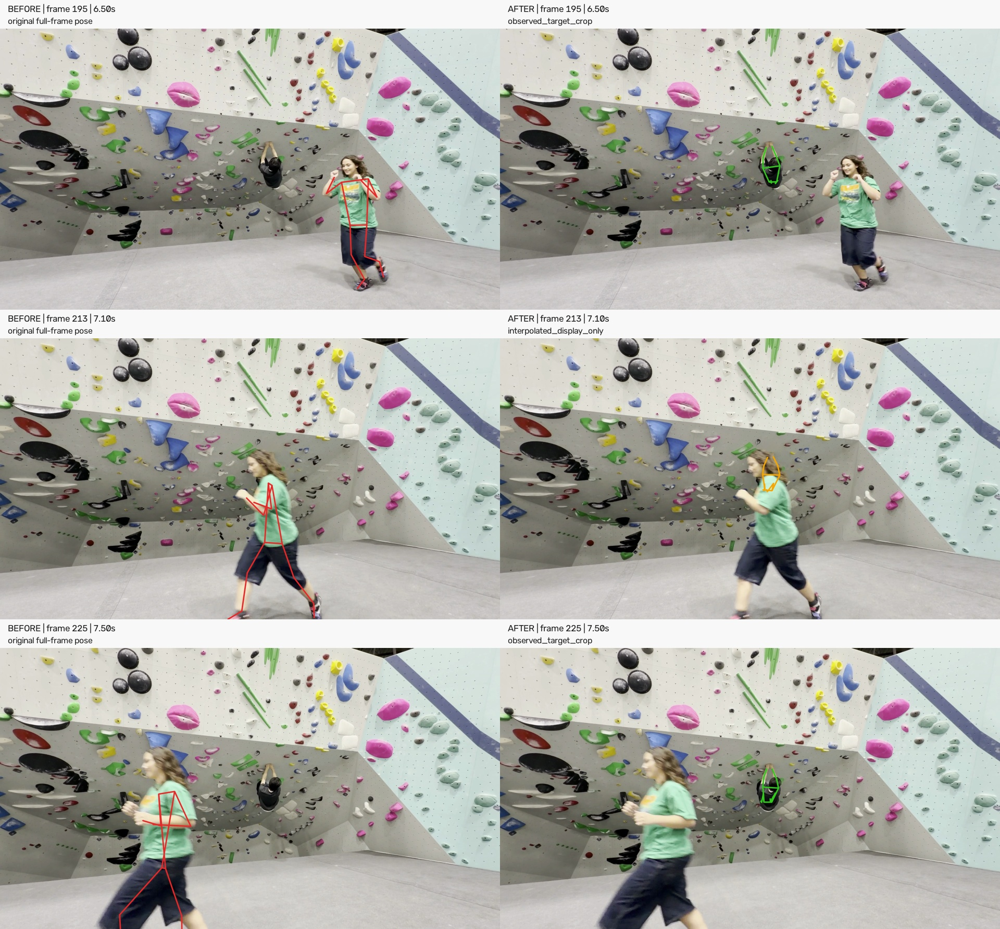

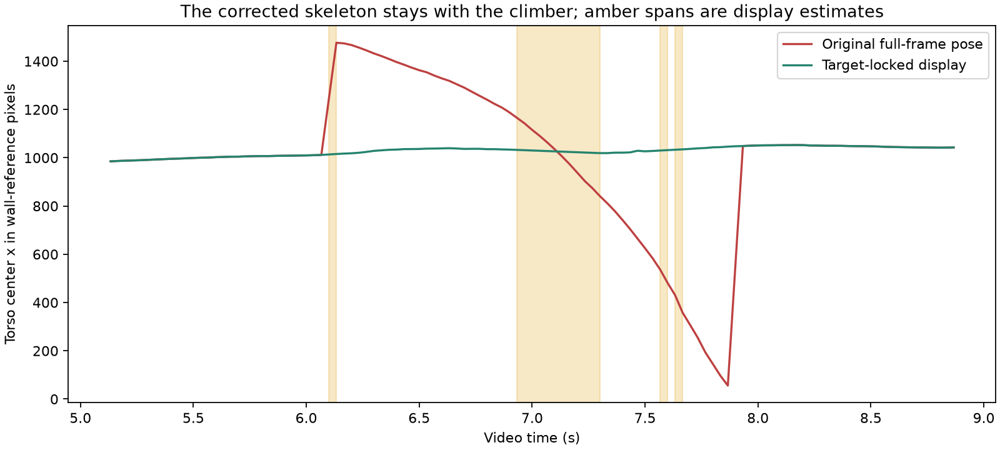

In [19]:
identity_report = subprocess.run([sys.executable, str(PROJECT_DIR / 'scripts/report_identity_tracking.py'),
    '--outputs', str(OUTPUTS_DIR)], cwd=PROJECT_DIR, capture_output=True, text=True)
if identity_report.returncode:
    raise RuntimeError(identity_report.stderr)
report = json.loads((STATE_DIR / 'identity_evaluation.json').read_text())
display(Markdown(report['notebook_markdown']))
display(Image(filename=str(IMAGES_DIR / 'identity_before_after.jpg'), width=1200))
display(Image(filename=str(IMAGES_DIR / 'identity_wall_displacement.png'), width=950))
display(Video(str(VIDEO_OUTPUT_DIR / 'identity_comparison_h264.mp4'), embed=True, width=1100))


## Geometry report: what the new measurements constrain

The 15 cm spacing assumption provides local scale; the reported 173 cm height describes the
original climber; the two parallel floor seams constrain one vanishing direction. The following
report separates those inputs from the camera and wall geometry that remain undetermined.


### Inputs and their meaning

- Adjacent-hole center spacing: **15 cm**, a user assumption, not a Movement specification or measurement.
- Filmed climber height: **173 cm**, reported by the user.
- Target user height: **190 cm**, kept separate for later retargeting.
- Default body ratios give model priors only; the climber's bent image height is not used as a ruler.

### Local scale from visible holes

The overlay marks the exact adjacent-hole pairs on the original video frame, before multi-frame compositing.
Each sample uses `pixel distance / (number of intervals * assumed spacing)`.
Row and column are image-grid directions, not world-horizontal or world-vertical axes.

| Wall region | Grid direction | Median local px/cm | Pairs |
|---|---|---:|---:|
| right_wall | column | 1.777 | 3 |
| right_wall | row | 2.188 | 3 |
| upper_wall | column | 2.166 | 3 |
| upper_wall | row | 2.189 | 3 |

Perspective makes these scales vary with position and direction. No single value is assigned to `PX_PER_CM`.
The spacing assumption does not establish a square grid or angles between grid directions.

### What the parallel floor lines tell us

The user identified F1 and F2 as parallel in the scene. Their image-line extensions give one
vanishing point: **(622.6, 708.1) pixels**, in frame-450 image coordinates.
This is a directional perspective constraint, not the floor horizon and not a wall-angle estimate.
Endpoint selection, lens distortion and curved mat seams affect the estimate.

To estimate a wall-to-floor angle, we still need the floor normal and the wall normal in the same
calibrated camera coordinates. For example: add a second floor-line family in another direction,
camera intrinsics, and known wall-grid geometry. A known vertical direction with camera calibration
is another way to constrain the floor normal. One known human height does not supply these by itself.

### Pipeline behavior

Section 4C saves assumptions, body priors, local measurements and the floor constraint. Section 8
shows them before the existing IK gate; Section 10 exports them. Contact predictions continue in
image coordinates. Metric IK remains pending until panel geometry and motion contacts are reviewed.
No wall angle, 3D wall reconstruction, physical success probability or contact-accuracy improvement is claimed.

Method references: [Single View Metrology](https://ora.ox.ac.uk/bookmarks/uuid%3A9b99df78-df75-49a9-a1b8-1b38e1b173a8),
[OpenCV planar homography](https://docs.opencv.org/4.x/d9/dab/tutorial_homography.html).


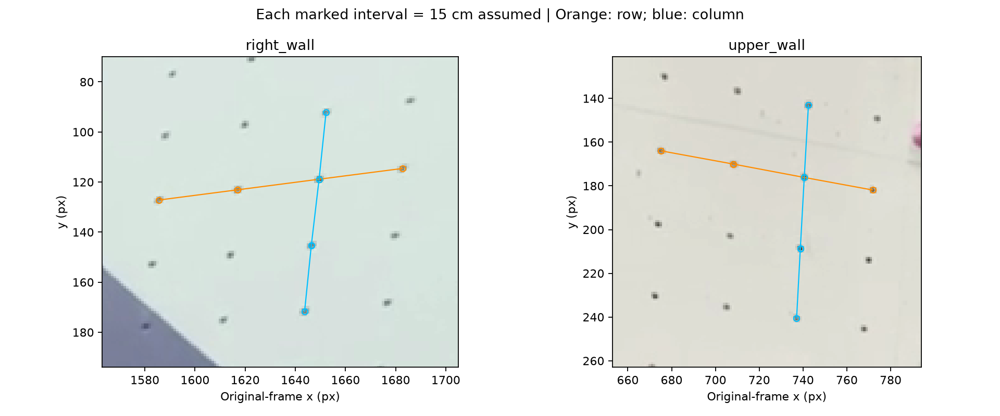

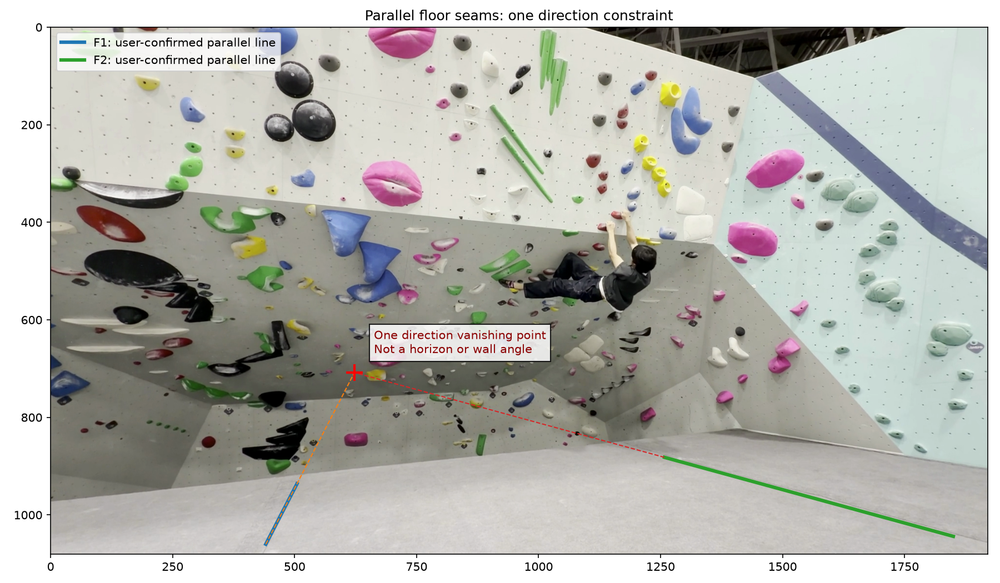

Standalone report: /Users/ziwei/Desktop/2026 Fall/CIS 5810/Beta_Translator/outputs/trial2/reports/geometry_calibration.html


In [9]:
geometry_context = load_geometry_run(OUTPUTS_DIR, VIDEO_FILE, GEOMETRY_REFERENCE_PATH,
    REFERENCE_FRAME, HOLE_SPACING_CM, SOURCE_CLIMBER_HEIGHT_CM, TARGET_HEIGHT_CM, RATIOS)
display(Markdown(geometry_context['notebook_markdown']))
display(Image(filename=str(IMAGES_DIR / 'geometry_hole_details.png'), width=1100))
display(Image(filename=str(IMAGES_DIR / 'floor_vanishing_point.png'), width=1200))
print('Standalone report:', OUTPUTS_DIR / 'reports/geometry_calibration.html')
